# Modelado base - BIODIVERSITY-GUARD-Predict
## Hito 3: línea base y modelos del Hito 2 reajustados

**Objetivo.** Medir **a qué hay que ganarle** antes de los modelos avanzados. Este notebook define la línea base con la definición nueva del Hito 3 (panel municipio-semana y nuevos targets) y reajusta los modelos del Hito 2 para poder compararlos. De aquí salen los criterios de éxito del modelado avanzado.

**Por qué se reajustan los modelos del Hito 2.** Las métricas del Hito 2 se midieron sobre otro problema (`area_ha`, vistas por alerta y por semana). El Hito 3 predice **focos de calor** (`y_7d`, `y_30d`) y la **clase de riesgo de fuego** (`clase_t1`) de la semana siguiente. Las unidades, las filas y los periodos son distintos, así que esas métricas **no son comparables** y los modelos se vuelven a ajustar con los datos nuevos.

**Entradas** (no se modifican): `datos/datasets_preparation/dataset_panel_PREPARADO.csv`, `parametros_preparacion.json`, `lista_features.json` y `kpi_parametros.json`. No se usan los `dataset_*_PREPARADO.csv` del Hito 2.

**Salidas:** `resultados/baseline_metricas.csv` y `resultados/baseline_predicciones_2025.csv`.

### Reglas de evaluación
1. **Solo 2022 a 2024 para decidir.** La prueba de 2025 se evalúa **una sola vez**, al final, con el modelo ajustado con todo el entrenamiento. 2026 no se toca en este notebook.
2. **Validación cruzada expansiva con 4 folds** (validación en 2023 S1, 2023 S2, 2024 S1 y 2024 S2). Cada fold entrena solo con filas anteriores al inicio de su validación menos **4 semanas de margen**, porque `y_30d` mira 4 semanas adelante.
3. El Frente 1 se entrena con `y_7d_log` e `y_30d_log` y se evalúa **en focos reales** con `expm1`, recortando a un mínimo de 0. El Frente 2 usa solo filas con `valido_f2`.
4. Los parámetros de preparación (escalador, recortes, `log1p`, medianas) ya están ajustados con el entrenamiento y **no se reajustan**. **Limitación:** se ajustaron con todo el entrenamiento y no por fold.
5. Semillas fijas (`random_state=42`) y versiones de las librerías impresas.


## Índice de figuras

| Figura | Título | Sección |
|---|---|---|
| 1 | MAE de la persistencia y de los modelos base por fold, validación cruzada 2023 a 2024 | 5. Métricas en validación cruzada |
| 2 | Matrices de confusión del Frente 2 en validación cruzada (proporción por fila), 2023 a 2024 | 5. Métricas en validación cruzada |
| 3 | Real contra predicho a 7 días, persistencia y mejor baseline, validación cruzada 2023 a 2024 | 5. Métricas en validación cruzada |
| 4 | Error por rango de focos reales a 7 días, validación cruzada 2023 a 2024 | 5. Métricas en validación cruzada |
| 5 | Matriz de confusión de la alerta (Muy elevado) a 7 días, conteo y proporción por fila, validación 2023 a 2024 | 5. Métricas en validación cruzada |
| 6 | Error absoluto del mejor baseline a 7 días por estado, validación cruzada 2023 a 2024 | 8. Análisis de errores del mejor baseline |


## Configuración del entorno


In [1]:
from pathlib import Path
import unicodedata

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 1. Entorno: Google Colab (Drive) o ejecucion local
# ---------------------------------------------------------------------------
USAR_DRIVE = True   # True en Colab; False para trabajar con la carpeta local del repositorio
BASE_DRIVE = Path("/content/drive/MyDrive/BIODIVERSITY_GUARD")

if USAR_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = BASE_DRIVE
    except ImportError:
        print("No se detecto Google Colab: se usa la raiz local del repositorio.")
        USAR_DRIVE = False

if not USAR_DRIVE:
    # la raiz es la primera carpeta (hacia arriba desde la actual) que contiene "datos"
    _aqui = Path.cwd().resolve()
    BASE = next((p for p in [_aqui, *_aqui.parents] if (p / "datos").is_dir()), None)
    if BASE is None:
        raise FileNotFoundError("No se encontro la carpeta 'datos' subiendo desde " + str(_aqui))

if not BASE.exists():
    raise FileNotFoundError(f"No existe BASE = {BASE}. Verifica la carpeta BIODIVERSITY_GUARD en Drive.")

# ---------------------------------------------------------------------------
# 2. Rutas (todas salen de BASE)
# ---------------------------------------------------------------------------
DIR_PREP = BASE / "datos" / "datasets_preprocesamiento"
DIR_BDQ = DIR_PREP / "BDQueimadas"
DIR_DETER = DIR_PREP / "DETER"
DIR_NASA = DIR_PREP / "NasaPower"
DIR_SISAM = DIR_PREP / "SISAM"
DIR_EDA = BASE / "datos" / "datasets_eda"

# ---------------------------------------------------------------------------
# 3. Constantes comunes (identicas en los 7 notebooks)
# ---------------------------------------------------------------------------
FECHA_INICIO_DATOS = "2022-01-01"
FECHA_FIN_EXTRACCION = "2026-11-01"      # DETER y BDQueimadas
PRIMERA_SEMANA = "2022-01-03"             # primer lunes con semana completa (2022-01-01 es sabado)
ULTIMA_SEMANA = "2026-10-19"              # lunes de la ultima semana completa (termina domingo 2026-10-25)
SATELITE_REFERENCIA = "AQUA_M-T"
ESTADOS_AMAZONIA_LEGAL = ["ACRE", "AMAPÁ", "AMAZONAS", "MARANHÃO", "MATO GROSSO", "PARÁ", "RONDÔNIA", "RORAIMA", "TOCANTINS"]
MAPA_UF = {"ACRE": "AC", "AMAPÁ": "AP", "AMAZONAS": "AM", "MARANHÃO": "MA", "MATO GROSSO": "MT", "PARÁ": "PA", "RONDÔNIA": "RO", "RORAIMA": "RR", "TOCANTINS": "TO"}
CORRECCIONES_MUNICIPIO = {"ELDORADO DOS CARAJAS": "ELDORADO DO CARAJAS", "SANTA ISABEL DO PARA": "SANTA IZABEL DO PARA"}
FECHA_CORTE_CENTROIDES = "2024-12-31"     # los centroides se fijan con focos hasta esta fecha

# ---------------------------------------------------------------------------
# 4. Funciones comunes
# ---------------------------------------------------------------------------
def normalizar_texto(texto):
    # mayusculas, sin tildes ni espacios sobrantes
    if pd.isna(texto):
        return texto
    texto = str(texto).upper().strip()
    return unicodedata.normalize("NFKD", texto).encode("ASCII", "ignore").decode("utf-8")


def semana_lunes(fecha):
    # lunes de la semana (lunes a domingo) de cada fecha; recibe una Serie de fechas
    f = pd.to_datetime(fecha).dt.normalize()
    return f - pd.to_timedelta(f.dt.day_of_week, unit="D")


SEMANAS = pd.date_range(PRIMERA_SEMANA, ULTIMA_SEMANA, freq="W-MON")   # calendario de semanas completas
assert len(SEMANAS) == 251, f"El calendario deberia tener 251 semanas y tiene {len(SEMANAS)}"
assert (SEMANAS.day_of_week == 0).all(), "Todas las semanas deben empezar en lunes"


def verificar_entradas(archivos):
    # imprime los archivos de entrada con su tamano y falla si falta alguno
    faltan = []
    for a in map(Path, archivos):
        if a.exists():
            print(f"  OK  {a.relative_to(BASE)}  ({a.stat().st_size / 1e6:,.1f} MB)")
        else:
            faltan.append(a)
    if faltan:
        lista = "\n".join(f"  - {a}" for a in faltan)
        raise FileNotFoundError("Faltan archivos de entrada (copialos a esas carpetas y vuelve a ejecutar):\n" + lista)


print("BASE:", BASE)
print("Calendario:", SEMANAS[0].date(), "a", SEMANAS[-1].date(), f"({len(SEMANAS)} semanas)")


No se detecto Google Colab: se usa la raiz local del repositorio.
BASE: C:\UPC-DOCS\CICLO7\MACHINE LEARNING\HITO3\BIODIVERSITY_GUARD
Calendario: 2022-01-03 a 2026-10-19 (251 semanas)


In [2]:
import json
import platform
import warnings

import matplotlib
import matplotlib.pyplot as plt
import scipy
import seaborn as sns
import sklearn
from matplotlib.patches import Patch
from sklearn.linear_model import LinearRegression
from sklearn.metrics import confusion_matrix, f1_score, r2_score, recall_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 70
pd.set_option("display.max_columns", None)

SEMILLA = 42
CLAVE = ["municipio_norm", "uf"]
DIR_PREPARATION = BASE / "datos" / "datasets_preparation"
DIR_RESULTADOS = BASE / "resultados"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)


def mostrar(tabla, decimales=3):
    # imprime una tabla con miles separados por coma y decimales controlados
    print(tabla.to_string(float_format=lambda v: f"{v:,.{decimales}f}"))


print("Versiones:", {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                     "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__})


Versiones: {'python': '3.11.0', 'pandas': '3.1.1', 'numpy': '2.2.4', 'scikit-learn': '1.7.2', 'scipy': '1.15.2', 'matplotlib': '3.10.3'}


## 1. Introducción, datos y particiones

Se carga el panel preparado y se confirma qué significan `particion` y `pliego_validacion` antes de usarlas. Las particiones deben coincidir con las del Data Preparation: **80,907** filas de entrenamiento y **27,693** de prueba 2025. Luego se construyen los 4 folds y se verifica con `assert` que no hay solape de fechas, que se respeta el margen de 4 semanas y que ningún fold toca 2025 ni 2026.


In [3]:
verificar_entradas([DIR_PREPARATION / n for n in ["dataset_panel_PREPARADO.csv", "parametros_preparacion.json", "lista_features.json", "kpi_parametros.json"]])
panel = pd.read_csv(DIR_PREPARATION / "dataset_panel_PREPARADO.csv", parse_dates=["semana"])
PARAMS = json.load(open(DIR_PREPARATION / "parametros_preparacion.json", encoding="utf-8"))
FEATURES = json.load(open(DIR_PREPARATION / "lista_features.json", encoding="utf-8"))
KPI = json.load(open(DIR_PREPARATION / "kpi_parametros.json", encoding="utf-8"))
assert panel.shape[0] == 136293, f"Filas inesperadas: {panel.shape}"
panel = panel.sort_values(CLAVE + ["semana"]).reset_index(drop=True)

print("Forma del panel preparado:", panel.shape)
print("\nValores de `particion` y filas (semanas, desde, hasta):")
resumen_particion = panel.groupby("particion").agg(filas=("semana", "size"), semanas=("semana", "nunique"), desde=("semana", "min"), hasta=("semana", "max"))
print(resumen_particion.loc[["entrenamiento", "margen", "prueba", "flujo_2026", "descartada"]].to_string())
print("\nValores de `pliego_validacion` (fold de validación; vacío = no es validación de ningún fold):")
print(panel["pliego_validacion"].value_counts(dropna=False).sort_index().to_string())
print("\nPartición de las filas con pliego_validacion:", panel.loc[panel["pliego_validacion"].notna(), "particion"].unique().tolist())

assert resumen_particion.loc["entrenamiento", "filas"] == 80907, "El entrenamiento debe tener 80,907 filas"
assert resumen_particion.loc["prueba", "filas"] == 27693, "La prueba 2025 debe tener 27,693 filas"
print("\nConteos coinciden con el Data Preparation: entrenamiento 80,907 y prueba 2025 27,693.")


  OK  datos\datasets_preparation\dataset_panel_PREPARADO.csv  (62.1 MB)
  OK  datos\datasets_preparation\parametros_preparacion.json  (0.0 MB)
  OK  datos\datasets_preparation\lista_features.json  (0.0 MB)
  OK  datos\datasets_preparation\kpi_parametros.json  (0.0 MB)


Forma del panel preparado: (136293, 69)

Valores de `particion` y filas (semanas, desde, hasta):
               filas  semanas      desde      hasta
particion                                          
entrenamiento  80907      149 2022-01-31 2024-12-02
margen          2172        4 2024-12-09 2024-12-30
prueba         27693       51 2025-01-06 2025-12-22
flujo_2026     22806       42 2026-01-05 2026-10-19
descartada      2715        5 2022-01-03 2025-12-29

Valores de `pliego_validacion` (fold de validación; vacío = no es validación de ningún fold):
pliego_validacion
1.0    14118
2.0    14118
3.0    14118
4.0    12489
NaN    81450

Partición de las filas con pliego_validacion: ['entrenamiento']

Conteos coinciden con el Data Preparation: entrenamiento 80,907 y prueba 2025 27,693.


In [4]:
SEMANAS_MARGEN = PARAMS["particiones"]["semanas_de_margen"]
FIN_ENTRENAMIENTO = pd.Timestamp(PARAMS["particiones"]["entrenamiento"][1])
es_entrenamiento = panel["particion"].eq("entrenamiento")


def construir_folds(datos, parametros):
    # indices de entrenamiento y validacion de cada fold, con las comprobaciones de no solape y de margen
    folds = []
    for p in parametros["pliegos"]:
        ini_e, fin_e = (pd.Timestamp(x) for x in p["entreno"])
        ini_v, fin_v = (pd.Timestamp(x) for x in p["validacion"])
        idx_e = datos.index[es_entrenamiento & datos["semana"].between(ini_e, fin_e)]
        idx_v = datos.index[datos["pliego_validacion"].eq(p["pliego"])]
        assert len(set(idx_e) & set(idx_v)) == 0, f"Fold {p['pliego']}: filas en entrenamiento y validación a la vez"
        assert datos.loc[idx_e, "semana"].max() < datos.loc[idx_v, "semana"].min(), f"Fold {p['pliego']}: solape de fechas"
        assert datos.loc[idx_e, "semana"].max() + pd.Timedelta(weeks=SEMANAS_MARGEN) < datos.loc[idx_v, "semana"].min(), \
            f"Fold {p['pliego']}: no se respeta el margen de 4 semanas (y_30d mira 4 semanas adelante)"
        assert datos.loc[idx_v, "semana"].between(ini_v, fin_v).all()
        assert datos.loc[list(idx_e) + list(idx_v), "semana"].max() <= FIN_ENTRENAMIENTO, "Un fold usa semanas posteriores al entrenamiento (2025 o 2026)"
        folds.append({"fold": p["pliego"], "idx_entreno": idx_e, "idx_valid": idx_v,
                      "entreno": (ini_e, datos.loc[idx_e, "semana"].max()), "validacion": (datos.loc[idx_v, "semana"].min(), datos.loc[idx_v, "semana"].max())})
    return folds


FOLDS = construir_folds(panel, PARAMS)
tabla_folds = pd.DataFrame([{"fold": f["fold"], "entreno_desde": f["entreno"][0].date(), "entreno_hasta": f["entreno"][1].date(),
                             "validacion_desde": f["validacion"][0].date(), "validacion_hasta": f["validacion"][1].date(),
                             "filas_entreno": len(f["idx_entreno"]), "filas_validacion": len(f["idx_valid"])} for f in FOLDS]).set_index("fold")
print("Folds de validación cruzada expansiva (verificado: sin solape, margen de 4 semanas y solo 2022 a 2024):")
print(tabla_folds.to_string())


Folds de validación cruzada expansiva (verificado: sin solape, margen de 4 semanas y solo 2022 a 2024):
     entreno_desde entreno_hasta validacion_desde validacion_hasta  filas_entreno  filas_validacion
fold                                                                                               
1       2022-01-31    2022-11-28       2023-01-02       2023-06-26          23892             14118
2       2022-01-31    2023-05-29       2023-07-03       2023-12-25          38010             14118
3       2022-01-31    2023-11-27       2024-01-01       2024-06-24          52128             14118
4       2022-01-31    2024-05-27       2024-07-01       2024-12-02          66246             12489


In [5]:
UMBRAL_SECA = KPI["nivel_focos_municipio_semana"]["valor"]["cortes_por_temporada"]["seca"]["p75"]
UMBRAL_HUMEDA = KPI["nivel_focos_municipio_semana"]["valor"]["cortes_por_temporada"]["humeda"]["p75"]
ORDINAL = {"Bajo": 0, "Moderado": 1, "Alto": 2, "Crítico": 3}
CLASES = list(ORDINAL)

# temporada de la semana objetivo (t+1): seca = julio a noviembre
panel["objetivo_seca"] = (panel["semana"] + pd.Timedelta(weeks=1)).dt.month.between(7, 11).astype(int)
panel["clase_t_ord"] = panel["clase_t"].map(ORDINAL)

# filas validas por frente
VALIDO = {"f1_7d": panel["valido_f1"].eq(1), "f1_30d": panel["valido_f1_30d"].eq(1), "f2": panel["valido_f2"].eq(1)}
OBJETIVO = {"f1_7d": ("y_7d", "y_7d_log"), "f1_30d": ("y_30d", "y_30d_log")}
LISTAS = {"f1": {"con": FEATURES["frente1_con_sisam"], "sin": FEATURES["frente1_sin_sisam"]},
          "f2": {"con": FEATURES["frente2_con_sisam"], "sin": FEATURES["frente2_sin_sisam"]}}
print(f"Umbral de alerta (Muy elevado, p75): húmeda {UMBRAL_HUMEDA:.0f} y seca {UMBRAL_SECA:.0f} focos por municipio-semana")
print("Features por lista:", {f"{f}_{s}": len(l) for f, d in LISTAS.items() for s, l in d.items()})
print("\nFilas válidas por frente en entrenamiento:", {k: int((v & es_entrenamiento).sum()) for k, v in VALIDO.items()})
print("Filas válidas por frente en prueba 2025:", {k: int((v & panel["particion"].eq("prueba")).sum()) for k, v in VALIDO.items()})


Umbral de alerta (Muy elevado, p75): húmeda 5 y seca 12 focos por municipio-semana
Features por lista: {'f1_con': 42, 'f1_sin': 37, 'f2_con': 44, 'f2_sin': 39}

Filas válidas por frente en entrenamiento: {'f1_7d': 80907, 'f1_30d': 80907, 'f2': 26027}
Filas válidas por frente en prueba 2025: {'f1_7d': 27693, 'f1_30d': 27693, 'f2': 6601}


### Hallazgos de esta etapa

**Qué se observa**
- El panel preparado tiene **136,293** filas y **69** columnas. Las particiones coinciden con el Data Preparation: entrenamiento **80,907** filas (**149** semanas), margen **2,172**, prueba 2025 **27,693** (**51** semanas) y flujo 2026 **22,806**, que no se toca.
- `pliego_validacion` vale 1 a 4 en **14,118**, **14,118**, **14,118** y **12,489** filas, y está vacío en **81,450**. Todas las filas con pliego son de la partición de entrenamiento.
- Los 4 folds entrenan con **23,892**, **38,010**, **52,128** y **66,246** filas y validan con **14,118**, **14,118**, **14,118** y **12,489**. Los `assert` de no solape, de margen de 4 semanas y de que ningún fold usa 2025 ni 2026 pasan.
- Filas válidas en entrenamiento: **80,907** para el Frente 1 y **26,027** para el Frente 2. En prueba: **27,693** y **6,601**.

**Por qué se decidió así**
- El margen de 4 semanas evita que la ventana de `y_30d` de las últimas semanas de entrenamiento entre en la validación.
- La alerta se define con el nivel Muy elevado: más de **5** focos en la temporada húmeda y más de **12** en la seca.

**Qué implica para el modelado avanzado**
- **Limitación:** los parámetros de preparación (escalador, recortes, `log1p` y medianas) se ajustaron con todo el entrenamiento y no por fold. Los modelos de árboles no se afectan por el escalado.


## 2. Métricas de desempeño iniciales

Esta sección define cada métrica que usa el proyecto. Los valores de referencia a vencer salen de estas métricas y se reúnen en el cuadro "Valores iniciales de referencia" de la sección 7. En las fórmulas, `y` es el valor real, `ŷ` el predicho y `n` el número de filas evaluadas.

### Frente 1 (regresión de focos)

| Métrica | Qué mide | Fórmula breve | Por qué se usa | Cómo se lee |
|---|---|---|---|---|
| MAE (en focos reales) | Error típico en focos por municipio-semana | promedio de `abs(ŷ - y)` | Se interpreta directo en focos y no se dispara con un solo pico | Más bajo es mejor |
| RMSE | Error típico penalizando los errores grandes | raíz del promedio de `(ŷ - y)^2` | Castiga fallar en los picos, que son lo más costoso | Más bajo es mejor |
| MAE solo en semanas con focos reales | Error en las filas donde `y` es mayor que 0 | promedio de `abs(ŷ - y)` con `y > 0` | Cerca de 7 de cada 10 filas son ceros y hacen que el MAE global parezca bajo | Más bajo es mejor |
| Sesgo medio | Si el modelo sobreestima o subestima | promedio de `ŷ - y` | Detecta subestimación sistemática de los picos | Cerca de 0 es mejor; negativo indica que subestima |
| R² en escala `log1p` | Qué parte de la variación (en escala log) se explica | `1 - suma((log1p y - log1p ŷ)^2) / suma((log1p y - media)^2)` | Es comparable entre horizontes y niveles de focos | Más alto es mejor; 0 equivale a predecir el promedio |

### Frente 2 (clasificación de la clase de riesgo, 0 a 3)

| Métrica | Qué mide | Fórmula breve | Por qué se usa | Cómo se lee |
|---|---|---|---|---|
| Accuracy | Porcentaje de filas con la clase correcta | aciertos dividido por `n` | Es la medida más simple, pero **engaña con clases desbalanceadas**: Bajo es cerca de la mitad de las filas | Más alto es mejor, con cautela |
| F1 macro | Promedio del F1 de las 4 clases, sin ponderar | promedio de `2 * precisión * recall / (precisión + recall)` por clase | Trata igual a las clases pequeñas y a las grandes | Más alto es mejor |
| F1 por clase | Equilibrio entre precisión y recall de cada clase | F1 de cada clase | Muestra qué clases se predicen peor | Más alto es mejor |
| Recall por clase | De las filas de una clase, cuántas se detectan | aciertos de la clase dividido por filas reales de la clase | Mide cuántos casos reales se encuentran | Más alto es mejor |
| Recall de Crítico | Recall de la clase más grave | recall de la clase 3 | Es el error más costoso: no avisar un riesgo Crítico | Más alto es mejor |
| Error ordinal medio | Distancia entre la clase real y la predicha | promedio de `abs(clase real - clase predicha)` | Confundir Bajo con Crítico es peor que confundir clases vecinas | Más bajo es mejor |

La **matriz de confusión** muestra, por fila (clase real), a qué clase se predijo; en proporciones por fila, la diagonal es el recall de cada clase.

### KPI de alerta (derivado del Frente 1 a 7 días)
La predicción de focos se convierte en alerta cuando supera el umbral del nivel Muy elevado de la temporada de la semana objetivo (**5** focos en la húmeda y **12** en la seca, de `kpi_parametros.json`). Se compara con la alerta real.

| Métrica | Qué mide | Fórmula breve | Por qué se usa | Cómo se lee |
|---|---|---|---|---|
| Recall de alerta | Alertas reales que se detectan | `VP / (VP + FN)` | Una alerta no detectada es un incendio grave sin aviso | Más alto es mejor |
| Precisión de alerta | De las alertas emitidas, cuántas eran reales | `VP / (VP + FP)` | Evita saturar a los equipos de respuesta | Más alto es mejor |
| Tasa de falsas alarmas | Semanas sin alerta real donde se emitió alerta | `FP / (FP + VN)` | Controla el costo de movilizar recursos en vano | Más bajo es mejor |

### Aclaraciones y criterio de lectura
- El **Frente 1 no tiene matriz de confusión directa**, porque es una regresión (no hay clases). Sus equivalentes son el gráfico de real contra predicho, los errores por rango de focos y por temporada, y la **matriz de confusión de la alerta**.
- **Criterio de lectura:** en MAE, RMSE y error ordinal, **más bajo es mejor**; en F1 macro, recall y R², **más alto es mejor**; en la alerta se busca **recall alto con falsas alarmas bajas**.
- Las métricas se calculan por fold de la validación cruzada y se reportan como promedio y desviación entre folds, y una sola vez en 2025.


### Hallazgos de esta etapa

**Qué se observa**
- Se definen las métricas del Frente 1 (MAE, RMSE, MAE en semanas con focos, sesgo y R² en `log1p`), del Frente 2 (accuracy, F1 macro, F1 y recall por clase, recall de Crítico y error ordinal) y del KPI de alerta (recall, precisión y tasa de falsas alarmas).
- Cada métrica trae su fórmula breve, su motivo y su criterio de lectura: MAE, RMSE y error ordinal más bajos son mejores; F1 macro, recall y R² más altos son mejores; en la alerta se busca recall alto con falsas alarmas bajas.

**Por qué importa**
- Ninguna métrica sola alcanza: el MAE global esconde que gran parte de las filas son ceros, y el accuracy esconde el desbalance de clases. Por eso se agregan el MAE en semanas con focos y el F1 macro.
- El Frente 1 no tiene matriz de confusión directa por ser una regresión: sus equivalentes son el gráfico de real contra predicho, el error por rango de focos y por temporada, y la matriz de confusión de la alerta.

**Qué implica para el modelado avanzado**
- Todo modelo se reporta con este mismo conjunto de métricas, para compararlo con los valores iniciales de la sección 7.


## 3. Baseline de persistencia (sin entrenar)

- **Frente 1 a 7 días:** predicción igual a los focos de la semana `t` (`num_incendios_crudo`).
- **Frente 1 a 30 días:** predicción igual a **4 veces** los focos de la semana `t`. **Supuesto:** las 4 semanas siguientes repiten el nivel de la semana actual.
- **Frente 2:** predicción igual a `clase_t`, la clase de riesgo de la semana actual. Solo está definida cuando la semana `t` tiene riesgo calculado, así que la persistencia se evalúa en ese subconjunto (`con_clase_t`).

Métricas: MAE, RMSE (en focos), MAE solo en semanas con focos reales y, para el Frente 2, accuracy y F1 macro. Se reportan por fold y promedio, y también sobre todo el entrenamiento junto, para **comparar con lo ya medido en el EDA** (MAE 3.343, RMSE 18.448 y accuracy de clase 66.1 %).


In [6]:
def metricas_f1(real, pred):
    # metricas de regresion en focos reales; el R2 se mide en escala log1p
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    error = pred - real
    con_focos = real > 0
    return {"MAE": np.abs(error).mean(), "RMSE": float(np.sqrt((error ** 2).mean())),
            "MAE_con_focos": np.abs(error[con_focos]).mean() if con_focos.any() else np.nan,
            "R2_log1p": r2_score(np.log1p(real), np.log1p(pred)), "sesgo": error.mean()}


def metricas_alerta(real, pred, es_seca):
    # alerta = focos por encima del p75 de la temporada de la semana objetivo (nivel Muy elevado)
    umbral = np.where(np.asarray(es_seca) == 1, UMBRAL_SECA, UMBRAL_HUMEDA)
    alerta_real, alerta_pred = np.asarray(real) > umbral, np.asarray(pred) > umbral
    tp, fp = (alerta_real & alerta_pred).sum(), (~alerta_real & alerta_pred).sum()
    fn, tn = (alerta_real & ~alerta_pred).sum(), (~alerta_real & ~alerta_pred).sum()
    return {"recall_alerta": tp / (tp + fn) if tp + fn else np.nan, "precision_alerta": tp / (tp + fp) if tp + fp else np.nan,
            "tasa_falsas_alarmas": fp / (fp + tn) if fp + tn else np.nan, "alertas_reales": int(tp + fn)}


def metricas_f2(real, pred):
    # metricas de clasificacion ordinal (clases 0 a 3)
    real, pred = np.asarray(real, int), np.asarray(pred, int)
    etiquetas = [0, 1, 2, 3]
    f1 = f1_score(real, pred, labels=etiquetas, average=None, zero_division=0)
    recall = recall_score(real, pred, labels=etiquetas, average=None, zero_division=0)
    salida = {"accuracy": float((real == pred).mean()), "F1_macro": float(f1.mean()), "error_ordinal": float(np.abs(real - pred).mean()),
              "recall_critico": float(recall[3])}
    for i, clase in enumerate(CLASES):
        salida[f"F1_{clase}"], salida[f"recall_{clase}"] = float(f1[i]), float(recall[i])
    return salida


REGISTROS = []      # una fila por metrica: frente, modelo, sisam, evaluacion, fold, subconjunto, metrica, valor
PREDICCIONES = []   # predicciones de validacion y de prueba, para analisis posteriores


def registrar(frente, modelo, sisam, evaluacion, fold, subconjunto, metricas):
    for nombre, valor in metricas.items():
        REGISTROS.append({"frente": frente, "modelo": modelo, "sisam": sisam, "evaluacion": evaluacion, "fold": fold,
                          "subconjunto": subconjunto, "metrica": nombre, "valor": float(valor)})


def guardar_predicciones(frente, modelo, sisam, evaluacion, fold, idx, real, pred, subconjunto="todas"):
    PREDICCIONES.append(pd.DataFrame({"idx": idx, "frente": frente, "modelo": modelo, "sisam": sisam, "evaluacion": evaluacion,
                                      "fold": fold, "subconjunto": subconjunto, "real": np.asarray(real, float), "pred": np.asarray(pred, float)}))


def persistencia(frente, idx):
    # prediccion de la persistencia para cada frente
    if frente == "f1_7d":
        return panel.loc[idx, "num_incendios_crudo"].to_numpy(float)
    if frente == "f1_30d":
        return 4 * panel.loc[idx, "num_incendios_crudo"].to_numpy(float)
    return panel.loc[idx, "clase_t_ord"].to_numpy(float)


In [7]:
def evaluar_persistencia(frente, idx, evaluacion, fold):
    # evalua la persistencia sobre las filas validas de idx y registra metricas y predicciones
    idx = idx[VALIDO[frente].loc[idx].to_numpy()]
    if frente.startswith("f1"):
        real = panel.loc[idx, OBJETIVO[frente][0]].to_numpy(float)
        pred = persistencia(frente, idx)
        registrar(frente, "persistencia", "no aplica", evaluacion, fold, "todas", metricas_f1(real, pred))
        if frente == "f1_7d":
            registrar(frente, "persistencia", "no aplica", evaluacion, fold, "todas", metricas_alerta(real, pred, panel.loc[idx, "objetivo_seca"]))
        guardar_predicciones(frente, "persistencia", "no aplica", evaluacion, fold, idx, real, pred)
    else:
        pred = persistencia(frente, idx)
        con_clase = ~np.isnan(pred)
        real = panel.loc[idx, "clase_t1_ord"].to_numpy(float)
        registrar(frente, "persistencia", "no aplica", evaluacion, fold, "con_clase_t", metricas_f2(real[con_clase], pred[con_clase]))
        guardar_predicciones(frente, "persistencia", "no aplica", evaluacion, fold, idx[con_clase], real[con_clase], pred[con_clase], "con_clase_t")


for fold in FOLDS:
    for frente in ["f1_7d", "f1_30d", "f2"]:
        evaluar_persistencia(frente, fold["idx_valid"], "cv_fold", fold["fold"])
# entrenamiento completo (todas las filas de entrenamiento), para comparar con el EDA
idx_entreno_total = panel.index[es_entrenamiento]
for frente in ["f1_7d", "f1_30d", "f2"]:
    evaluar_persistencia(frente, idx_entreno_total, "entrenamiento_completo", 0)

resultados = pd.DataFrame(REGISTROS)
per = resultados[resultados["modelo"] == "persistencia"]
print("Persistencia por fold (validación cruzada):")
for frente, metricas in [("f1_7d", ["MAE", "RMSE", "MAE_con_focos"]), ("f1_30d", ["MAE", "RMSE", "MAE_con_focos"]), ("f2", ["accuracy", "F1_macro"])]:
    t = per[(per["frente"] == frente) & (per["evaluacion"] == "cv_fold") & per["metrica"].isin(metricas)].pivot_table(index="fold", columns="metrica", values="valor")[metricas]
    t.loc["promedio"] = t.mean()
    t.loc["desv_estandar"] = t.iloc[:4].std()
    print(f"\n{frente}:")
    mostrar(t, 3)


Persistencia por fold (validación cruzada):



f1_7d:
metrica         MAE   RMSE  MAE_con_focos
fold                                     
1             0.599  2.362          3.040
2             5.210 19.121          9.451
3             1.057  6.798          4.958
4             6.977 28.539         12.487
promedio      3.461 14.205          7.484
desv_estandar 3.130 11.899          4.283

f1_30d:
metrica          MAE    RMSE  MAE_con_focos
fold                                       
1              2.671  11.074          7.656
2             19.781  69.872         26.067
3              4.460  25.572         12.043
4             32.097 146.216         41.192
promedio      14.752  63.183         21.740
desv_estandar 13.881  60.743         15.160

f2:
metrica        accuracy  F1_macro
fold                             
1                 0.743     0.474
2                 0.616     0.567
3                 0.739     0.564
4                 0.647     0.618
promedio          0.686     0.555
desv_estandar     0.064     0.060


In [8]:
EDA_MAE, EDA_RMSE, EDA_ACC = 3.343, 18.448, 0.661
completo = per[per["evaluacion"] == "entrenamiento_completo"].pivot_table(index="frente", columns="metrica", values="valor")
filas_f1 = int(VALIDO["f1_7d"][es_entrenamiento].sum())
print(f"Persistencia a 7 días sobre todo el entrenamiento ({filas_f1:,} filas): MAE {completo.loc['f1_7d', 'MAE']:.3f} | RMSE {completo.loc['f1_7d', 'RMSE']:.3f}")
print(f"Valores del EDA (81,450 filas): MAE {EDA_MAE:.3f} | RMSE {EDA_RMSE:.3f}")
print(f"Diferencia: MAE {completo.loc['f1_7d', 'MAE'] - EDA_MAE:+.3f} | RMSE {completo.loc['f1_7d', 'RMSE'] - EDA_RMSE:+.3f}")
pares = int((VALIDO["f2"] & es_entrenamiento & panel["clase_t_ord"].notna()).sum())
print(f"\nPersistencia de clase sobre todo el entrenamiento ({pares:,} pares con riesgo en ambas semanas): accuracy {completo.loc['f2', 'accuracy'] * 100:.1f} % (EDA: {EDA_ACC * 100:.1f} % con 18,017 pares)")
print("\nCausa de la diferencia: el EDA usaba las semanas 2022-01-03 a 2024-12-02 con media móvil disponible (81,450 filas), mientras que aquí el entrenamiento")
print(f"empieza el 2022-01-31 ({filas_f1:,} filas, sin las 4 primeras semanas). Es el mismo baseline sobre un conjunto de filas un poco distinto.")


Persistencia a 7 días sobre todo el entrenamiento (80,907 filas): MAE 3.364 | RMSE 18.510
Valores del EDA (81,450 filas): MAE 3.343 | RMSE 18.448
Diferencia: MAE +0.021 | RMSE +0.062

Persistencia de clase sobre todo el entrenamiento (17,884 pares con riesgo en ambas semanas): accuracy 65.9 % (EDA: 66.1 % con 18,017 pares)

Causa de la diferencia: el EDA usaba las semanas 2022-01-03 a 2024-12-02 con media móvil disponible (81,450 filas), mientras que aquí el entrenamiento
empieza el 2022-01-31 (80,907 filas, sin las 4 primeras semanas). Es el mismo baseline sobre un conjunto de filas un poco distinto.


### Hallazgos de esta etapa

**Qué se observa**
- A 7 días, la persistencia da un MAE de **3.461** (desviación entre folds **3.130**), un RMSE de **14.205** y un MAE solo en semanas con focos de **7.484**. Por fold, el MAE va de **0.599** (fold 1) a **6.977** (fold 4).
- A 30 días (4 veces los focos de la semana `t`), el MAE es **14.752** (desviación **13.881**), con valores de **2.671** a **32.097** entre folds.
- Para el Frente 2, la persistencia de clase da accuracy **0.686** y F1 macro **0.555**.
- Coincide con lo medido en el EDA: sobre todo el entrenamiento el MAE es **3.364** y el RMSE **18.510** (EDA: **3.343** y **18.448**), y el accuracy de clase **65.9 %** sobre **17,884** pares (EDA: **66.1 %** con **18,017**).

**Por qué importa**
- La diferencia con el EDA (**+0.021** de MAE) se explica por las filas: aquí el entrenamiento empieza el 2022-01-31 (**80,907** filas) y el EDA usaba **81,450**.
- El nivel de focos cambia mucho entre folds (el fold 4 es la temporada seca de 2024), por eso el MAE de un mismo baseline va de **0.599** a **6.977**.

**Qué implica para el modelado avanzado**
- Esta es la línea base sin entrenar: todo modelo debe ganarle a la persistencia.
- **Limitación:** con desviaciones entre folds tan altas, las comparaciones deben hacerse fold por fold y no solo con el promedio.


## 4. Modelos base del Hito 2, reajustados

- **Frente 1:** Regresión Lineal y Árbol de Regresión (`max_depth=8`), para `y_7d_log` e `y_30d_log`.
- **Frente 2:** Árbol de Decisión (`max_depth=8`) con y sin `class_weight='balanced'`.
- Cada modelo se corre con `features_con_sisam` y con `features_sin_sisam` (listas de `lista_features.json`), como **primera lectura** del aporte de SISAM. La ablación completa se hace en el notebook avanzado.
- En cada fold, el entrenamiento usa solo las filas anteriores a la validación menos el margen de 4 semanas. Después se hace un ajuste final con todo el entrenamiento, que se usa solo para la prueba de 2025 (sección 6). El Frente 1 se predice en escala log, se aplica `expm1` y se recorta a un mínimo de 0.


In [9]:
MODELOS_F1 = {"lineal": lambda: LinearRegression(), "arbol": lambda: DecisionTreeRegressor(max_depth=8, random_state=SEMILLA)}
MODELOS_F2 = {"arbol": lambda: DecisionTreeClassifier(max_depth=8, random_state=SEMILLA),
              "arbol_balanceado": lambda: DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=SEMILLA)}


def ajustar_y_evaluar(frente, nombre, sisam, idx_entreno, idx_eval, evaluacion, fold):
    # ajusta un modelo con idx_entreno (filas validas) y lo evalua en idx_eval; registra metricas y predicciones
    idx_entreno = idx_entreno[VALIDO[frente].loc[idx_entreno].to_numpy()]
    idx_eval = idx_eval[VALIDO[frente].loc[idx_eval].to_numpy()]
    if frente.startswith("f1"):
        columnas = LISTAS["f1"][sisam]
        col_real, col_log = OBJETIVO[frente]
        modelo = MODELOS_F1[nombre]().fit(panel.loc[idx_entreno, columnas], panel.loc[idx_entreno, col_log])
        pred = np.clip(np.expm1(modelo.predict(panel.loc[idx_eval, columnas])), 0, None)
        real = panel.loc[idx_eval, col_real].to_numpy(float)
        registrar(frente, nombre, sisam, evaluacion, fold, "todas", metricas_f1(real, pred))
        if frente == "f1_7d":
            registrar(frente, nombre, sisam, evaluacion, fold, "todas", metricas_alerta(real, pred, panel.loc[idx_eval, "objetivo_seca"]))
        guardar_predicciones(frente, nombre, sisam, evaluacion, fold, idx_eval, real, pred)
    else:
        columnas = LISTAS["f2"][sisam]
        modelo = MODELOS_F2[nombre]().fit(panel.loc[idx_entreno, columnas], panel.loc[idx_entreno, "clase_t1_ord"].astype(int))
        pred = modelo.predict(panel.loc[idx_eval, columnas]).astype(float)
        real = panel.loc[idx_eval, "clase_t1_ord"].to_numpy(float)
        registrar(frente, nombre, sisam, evaluacion, fold, "todas", metricas_f2(real, pred))
        guardar_predicciones(frente, nombre, sisam, evaluacion, fold, idx_eval, real, pred, "todas")
        con_clase = panel.loc[idx_eval, "clase_t_ord"].notna().to_numpy()
        registrar(frente, nombre, sisam, evaluacion, fold, "con_clase_t", metricas_f2(real[con_clase], pred[con_clase]))
        guardar_predicciones(frente, nombre, sisam, evaluacion, fold, idx_eval[con_clase], real[con_clase], pred[con_clase], "con_clase_t")
    return modelo


for fold in FOLDS:
    for frente in ["f1_7d", "f1_30d"]:
        for nombre in MODELOS_F1:
            for sisam in ["con", "sin"]:
                ajustar_y_evaluar(frente, nombre, sisam, fold["idx_entreno"], fold["idx_valid"], "cv_fold", fold["fold"])
    for nombre in MODELOS_F2:
        for sisam in ["con", "sin"]:
            ajustar_y_evaluar("f2", nombre, sisam, fold["idx_entreno"], fold["idx_valid"], "cv_fold", fold["fold"])
    print(f"Fold {fold['fold']} listo: entrena {len(fold['idx_entreno']):,} filas, valida {len(fold['idx_valid']):,}")
resultados = pd.DataFrame(REGISTROS)
print("\nModelos ajustados por fold:", resultados.query("evaluacion == 'cv_fold'").groupby(["frente", "modelo", "sisam"]).ngroups, "combinaciones (frente, modelo, lista de features)")


Fold 1 listo: entrena 23,892 filas, valida 14,118


Fold 2 listo: entrena 38,010 filas, valida 14,118


Fold 3 listo: entrena 52,128 filas, valida 14,118


Fold 4 listo: entrena 66,246 filas, valida 12,489

Modelos ajustados por fold: 15 combinaciones (frente, modelo, lista de features)


### Hallazgos de esta etapa

**Qué se observa**
- Se ajustaron **15** combinaciones de frente, modelo y lista de features en cada fold, con el entrenamiento creciendo de **23,892** a **66,246** filas.
- Cada modelo se corrió con `features_con_sisam` y `features_sin_sisam`, y después se hizo un ajuste final con todo el entrenamiento para la prueba de 2025.

**Por qué se decidió así**
- El entrenamiento de cada fold usa solo filas anteriores a su validación menos 4 semanas, así que ningún modelo ve datos del futuro.
- El Frente 1 se entrena en escala `log1p` y se evalúa en focos reales, con `expm1` y un mínimo de 0.

**Qué implica para el modelado avanzado**
- Los mismos folds y las mismas funciones de evaluación deben usarse en el notebook avanzado, para que las comparaciones sean directas.


## 5. Métricas en validación cruzada

- **Frente 1:** MAE y RMSE en focos reales, MAE solo en semanas con focos reales, R² en escala `log1p` y sesgo medio (predicho menos real). Promedio y desviación estándar **entre folds**.
- **Frente 2:** accuracy, F1 macro, F1 y recall por clase, recall de Crítico y error ordinal medio (diferencia absoluta entre clases 0 a 3). La matriz de confusión se muestra en proporciones por fila, con las predicciones de los 4 folds juntas.
- **KPI de alerta:** la predicción de focos a 7 días se convierte en alerta cuando supera el umbral de Muy elevado de la temporada de la semana objetivo (húmeda 5 y seca 12 focos por municipio-semana). Se calculan recall de alerta, precisión y **tasa de falsas alarmas** (falsas alarmas divididas por todas las semanas sin alerta real).


In [10]:
def resumen_cv(frente, subconjunto, metricas):
    # promedio y desviacion estandar entre folds para cada modelo y lista de features
    r = resultados[(resultados["frente"] == frente) & (resultados["evaluacion"] == "cv_fold") & (resultados["subconjunto"] == subconjunto)
                   & resultados["metrica"].isin(metricas)]
    return r.pivot_table(index=["modelo", "sisam"], columns="metrica", values="valor", aggfunc=["mean", "std"])[[(a, m) for m in metricas for a in ["mean", "std"]]]


def como_texto(tabla, decimales=3):
    # 'promedio +/- desviacion' en una sola columna por metrica
    metricas = list(dict.fromkeys(m for _, m in tabla.columns))
    return pd.DataFrame({m: [f"{a:.{decimales}f} +/- {b:.{decimales}f}" for a, b in zip(tabla[("mean", m)], tabla[("std", m)])] for m in metricas}, index=tabla.index)


for frente, titulo in [("f1_7d", "Frente 1 a 7 días (y_7d), en focos reales"), ("f1_30d", "Frente 1 a 30 días (y_30d), en focos reales")]:
    print(f"{titulo}. Promedio +/- desviación estándar entre los 4 folds:")
    print(como_texto(resumen_cv(frente, "todas", ["MAE", "RMSE", "MAE_con_focos", "R2_log1p", "sesgo"])).to_string())
    print()


Frente 1 a 7 días (y_7d), en focos reales. Promedio +/- desviación estándar entre los 4 folds:
                                    MAE               RMSE    MAE_con_focos         R2_log1p             sesgo
modelo       sisam                                                                                            
arbol        con        3.383 +/- 3.115  15.093 +/- 13.672  7.239 +/- 4.407  0.490 +/- 0.105  -1.308 +/- 1.349
             sin        3.357 +/- 3.098  14.980 +/- 13.690  7.169 +/- 4.406  0.493 +/- 0.103  -1.286 +/- 1.296
lineal       con        3.274 +/- 3.134  15.376 +/- 15.049  7.019 +/- 4.541  0.561 +/- 0.073  -2.025 +/- 2.010
             sin        3.281 +/- 3.160  15.728 +/- 15.873  7.015 +/- 4.634  0.562 +/- 0.076  -2.140 +/- 2.271
persistencia no aplica  3.461 +/- 3.130  14.205 +/- 11.899  7.484 +/- 4.283  0.399 +/- 0.113  -0.022 +/- 0.025

Frente 1 a 30 días (y_30d), en focos reales. Promedio +/- desviación estándar entre los 4 folds:
                              

In [11]:
print("Frente 1 a 7 días: KPI de alerta (Muy elevado), promedio +/- desviación estándar entre folds:")
print(como_texto(resumen_cv("f1_7d", "todas", ["recall_alerta", "precision_alerta", "tasa_falsas_alarmas"])).to_string())
print("\nAlertas reales por fold (persistencia):")
print(resultados.query("modelo == 'persistencia' and frente == 'f1_7d' and evaluacion == 'cv_fold' and metrica == 'alertas_reales'")[["fold", "valor"]].set_index("fold").T.to_string())


Frente 1 a 7 días: KPI de alerta (Muy elevado), promedio +/- desviación estándar entre folds:
                          recall_alerta precision_alerta tasa_falsas_alarmas
modelo       sisam                                                          
arbol        con        0.466 +/- 0.071  0.667 +/- 0.076     0.018 +/- 0.011
             sin        0.468 +/- 0.074  0.661 +/- 0.061     0.019 +/- 0.013
lineal       con        0.436 +/- 0.076  0.743 +/- 0.029     0.014 +/- 0.012
             sin        0.448 +/- 0.073  0.738 +/- 0.025     0.014 +/- 0.011
persistencia no aplica  0.579 +/- 0.083  0.591 +/- 0.065     0.033 +/- 0.021

Alertas reales por fold (persistencia):
fold       1       2      3       4
valor  373.0  1638.0  582.0  1685.0


In [12]:
for subconjunto, texto in [("con_clase_t", "filas con clase de la semana actual (la persistencia está definida)"), ("todas", "todas las filas con valido_f2")]:
    print(f"Frente 2, {texto}. Promedio +/- desviación estándar entre folds:")
    print(como_texto(resumen_cv("f2", subconjunto, ["accuracy", "F1_macro", "recall_critico", "error_ordinal"])).to_string())
    print()
print("Frente 2 (filas con clase de la semana actual): F1 y recall por clase, promedio entre folds:")
por_clase = resumen_cv("f2", "con_clase_t", [f"{p}_{c}" for c in CLASES for p in ["F1", "recall"]])
mostrar(por_clase.xs("mean", axis=1, level=0), 3)


Frente 2, filas con clase de la semana actual (la persistencia está definida). Promedio +/- desviación estándar entre folds:
                                   accuracy         F1_macro   recall_critico    error_ordinal
modelo           sisam                                                                        
arbol            con        0.651 +/- 0.076  0.519 +/- 0.058  0.456 +/- 0.203  0.450 +/- 0.105
                 sin        0.650 +/- 0.079  0.521 +/- 0.059  0.457 +/- 0.198  0.449 +/- 0.108
arbol_balanceado con        0.615 +/- 0.084  0.511 +/- 0.053  0.425 +/- 0.251  0.477 +/- 0.113
                 sin        0.604 +/- 0.081  0.497 +/- 0.060  0.404 +/- 0.277  0.491 +/- 0.106
persistencia     no aplica  0.686 +/- 0.064  0.555 +/- 0.060  0.545 +/- 0.261  0.393 +/- 0.072

Frente 2, todas las filas con valido_f2. Promedio +/- desviación estándar entre folds:
                               accuracy         F1_macro   recall_critico    error_ordinal
modelo           sisam         

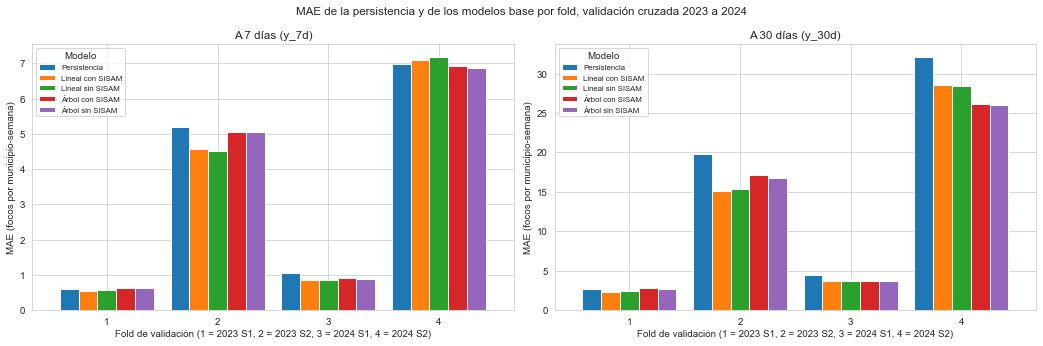

In [13]:
def predicciones_cv(frente, subconjunto):
    # predicciones de los 4 folds de validacion, juntas
    p = pd.concat(PREDICCIONES, ignore_index=True)
    return p[(p["frente"] == frente) & (p["evaluacion"] == "cv_fold") & (p["subconjunto"] == subconjunto)]


ETIQUETA_MODELO = {("persistencia", "no aplica"): "Persistencia", ("lineal", "con"): "Lineal con SISAM", ("lineal", "sin"): "Lineal sin SISAM",
                   ("arbol", "con"): "Árbol con SISAM", ("arbol", "sin"): "Árbol sin SISAM",
                   ("arbol_balanceado", "con"): "Árbol balanceado con SISAM", ("arbol_balanceado", "sin"): "Árbol balanceado sin SISAM"}
mae_fold = (resultados[(resultados["evaluacion"] == "cv_fold") & (resultados["metrica"] == "MAE")]
            .assign(modelo_etiqueta=lambda d: [ETIQUETA_MODELO[(m, s)] for m, s in zip(d["modelo"], d["sisam"])]))

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for eje, frente, titulo in [(ejes[0], "f1_7d", "A 7 días (y_7d)"), (ejes[1], "f1_30d", "A 30 días (y_30d)")]:
    tabla = mae_fold[mae_fold["frente"] == frente].pivot_table(index="fold", columns="modelo_etiqueta", values="valor")
    tabla = tabla[[c for c in ETIQUETA_MODELO.values() if c in tabla.columns]]
    tabla.plot(kind="bar", ax=eje, width=0.85)
    eje.set_title(titulo)
    eje.set_xlabel("Fold de validación (1 = 2023 S1, 2 = 2023 S2, 3 = 2024 S1, 4 = 2024 S2)")
    eje.set_ylabel("MAE (focos por municipio-semana)")
    eje.legend(title="Modelo", fontsize=8)
    plt.setp(eje.get_xticklabels(), rotation=0)
fig.suptitle("MAE de la persistencia y de los modelos base por fold, validación cruzada 2023 a 2024")
plt.tight_layout()
plt.show()


**Figura 1.** MAE en focos reales de la persistencia y de los modelos base (con y sin SISAM) en cada uno de los 4 folds de validación, a 7 y a 30 días. Subconjunto: validación cruzada 2023 a 2024.


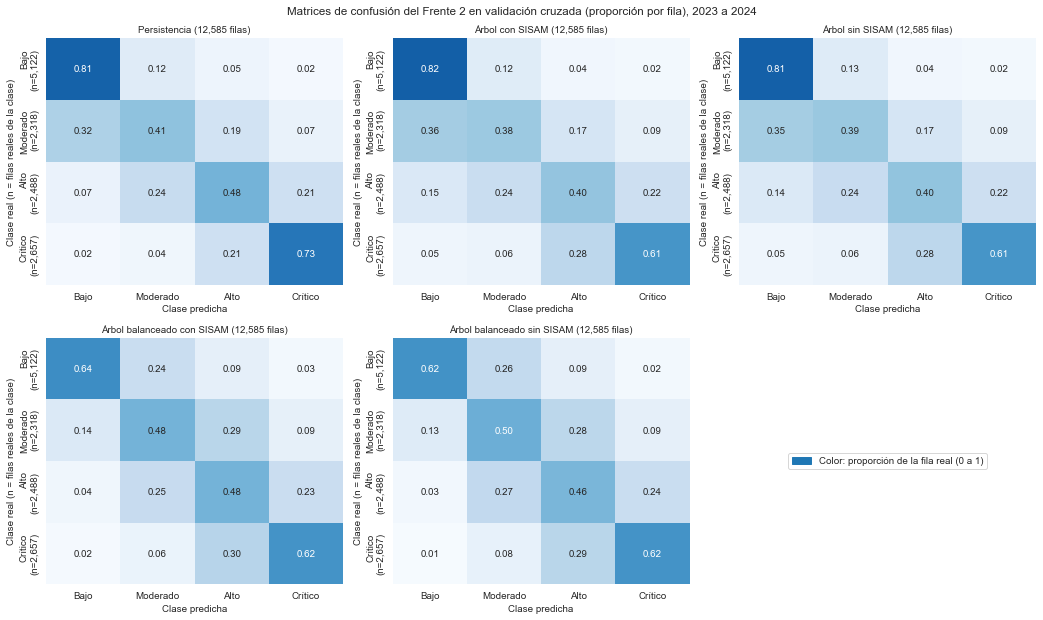

In [14]:
def matriz_confusion_filas(frente_pred):
    m = confusion_matrix(frente_pred["real"].astype(int), frente_pred["pred"].astype(int), labels=[0, 1, 2, 3]).astype(float)
    return m / m.sum(axis=1, keepdims=True)


modelos_f2 = [("persistencia", "no aplica"), ("arbol", "con"), ("arbol", "sin"), ("arbol_balanceado", "con"), ("arbol_balanceado", "sin")]
cv_f2 = predicciones_cv("f2", "con_clase_t")
fig, ejes = plt.subplots(2, 3, figsize=(15, 9))
for eje, (m, s) in zip(ejes.ravel(), modelos_f2):
    p = cv_f2[(cv_f2["modelo"] == m) & (cv_f2["sisam"] == s)]
    conteos = p["real"].astype(int).value_counts().reindex([0, 1, 2, 3]).fillna(0).astype(int)
    etiquetas_filas = [f"{c}\n(n={n:,})" for c, n in zip(CLASES, conteos)]
    sns.heatmap(matriz_confusion_filas(p), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASES, yticklabels=etiquetas_filas,
                         ax=eje, cbar=False)
    eje.set_title(f"{ETIQUETA_MODELO[(m, s)]} ({len(p):,} filas)", fontsize=10)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real (n = filas reales de la clase)")
ejes.ravel()[5].axis("off")
ejes.ravel()[5].legend(handles=[Patch(color="tab:blue", label="Color: proporción de la fila real (0 a 1)")], loc="center")
fig.suptitle("Matrices de confusión del Frente 2 en validación cruzada (proporción por fila), 2023 a 2024")
plt.tight_layout()
plt.show()


**Figura 2.** Matrices de confusión del Frente 2 (cada fila suma 1) para la persistencia y los árboles, con las predicciones de los 4 folds juntas y solo las filas con clase de la semana actual. Validación cruzada 2023 a 2024.


In [15]:
def conteo_clases(idx, subconjunto):
    # conteo y porcentaje de cada clase real (clase_t1) en las filas indicadas
    filas = panel.loc[idx]
    filas = filas[filas["valido_f2"] == 1]
    if subconjunto == "con_clase_t":
        filas = filas[filas["clase_t_ord"].notna()]
    n = filas["clase_t1_ord"].astype(int).value_counts().reindex([0, 1, 2, 3]).fillna(0).astype(int)
    return n.tolist() + [int(n.sum())] + (n / n.sum() * 100).round(1).tolist()


idx_prueba_descriptivo = panel.index[panel["particion"].eq("prueba")]
idx_validacion_total = panel.index[panel["pliego_validacion"].notna()]
filas_clases = {
    "Validación 2023-2024, todas las filas válidas": conteo_clases(idx_validacion_total, "todas"),
    "Validación 2023-2024, filas con clase de la semana actual": conteo_clases(idx_validacion_total, "con_clase_t"),
    "Prueba 2025, todas las filas válidas": conteo_clases(idx_prueba_descriptivo, "todas"),
    "Prueba 2025, filas con clase de la semana actual": conteo_clases(idx_prueba_descriptivo, "con_clase_t"),
}
tabla_clases = pd.DataFrame(filas_clases, index=[f"n_{c}" for c in CLASES] + ["n_total"] + [f"pct_{c}" for c in CLASES]).T
print("Clase real de la semana siguiente (conteo y porcentaje por clase):")
print(tabla_clases.to_string(float_format=lambda v: f"{v:,.1f}"))


Clase real de la semana siguiente (conteo y porcentaje por clase):
                                                           n_Bajo  n_Moderado  n_Alto  n_Crítico  n_total  pct_Bajo  pct_Moderado  pct_Alto  pct_Crítico
Validación 2023-2024, todas las filas válidas             8,238.0     2,895.0 3,116.0    3,852.0 18,101.0      45.5          16.0      17.2         21.3
Validación 2023-2024, filas con clase de la semana actual 5,122.0     2,318.0 2,488.0    2,657.0 12,585.0      40.7          18.4      19.8         21.1
Prueba 2025, todas las filas válidas                      2,742.0     1,151.0 1,345.0    1,363.0  6,601.0      41.5          17.4      20.4         20.6
Prueba 2025, filas con clase de la semana actual          1,349.0       830.0   924.0      810.0  3,913.0      34.5          21.2      23.6         20.7


### Hallazgos de esta etapa

**Qué se observa**
- **A 7 días** (ver Figura 1), el mejor modelo es la Regresión Lineal con SISAM (MAE **3.274**), seguida de la lineal sin SISAM (**3.281**), el árbol sin SISAM (**3.357**) y con SISAM (**3.383**). La persistencia da **3.461**. En RMSE ocurre lo contrario: la persistencia es mejor (**14.205**) que la lineal (**15.376**) y el árbol (**15.093**). El R² en `log1p` es **0.561** para la lineal y **0.399** para la persistencia. Los modelos subestiman: sesgo de **-2.025** (lineal) y **-1.308** (árbol).
- **A 30 días**, el mejor es el árbol sin SISAM (MAE **12.271**), frente a **12.451** de la lineal con SISAM y **14.752** de la persistencia.
- **SISAM:** con y sin SISAM los MAE difieren menos de 0.2 (por ejemplo **12.444** frente a **12.271** en el árbol a 30 días), mucho menos que la desviación entre folds a 7 días (**3.134** en la lineal con SISAM).
- **KPI de alerta a 7 días:** la persistencia tiene recall **0.579**, precisión **0.591** y tasa de falsas alarmas **0.033**. La lineal con SISAM tiene **0.436**, **0.743** y **0.014**. Hay **373**, **1,638**, **582** y **1,685** alertas reales por fold.
- **Frente 2** (ver Figura 2): la persistencia (accuracy **0.686**, F1 macro **0.555**, recall de Crítico **0.545**, error ordinal **0.393**) supera a los árboles (**0.651**, **0.519**, **0.456**, **0.450** el árbol con SISAM). El árbol balanceado sube el recall de Moderado (**0.492** frente a **0.379**) pero baja el de Bajo (**0.686** frente a **0.831**). Moderado es la clase más difícil (F1 de **0.413** en la persistencia).

- **Clases reales de la semana siguiente** (conteo en validación, todas las filas válidas): Bajo **8,238** (**45.5 %**), Moderado **2,895** (**16.0 %**), Alto **3,116** (**17.2 %**) y Crítico **3,852** (**21.3 %**). En 2025 los porcentajes son **41.5 %**, **17.4 %**, **20.4 %** y **20.6 %**. Con la clase de la semana actual disponible, en validación son **40.7 %**, **18.4 %**, **19.8 %** y **21.1 %**, y en 2025 **34.5 %**, **21.2 %**, **23.6 %** y **20.7 %**.

**Por qué importa**
- Bajo pesa cerca de la mitad de las filas, por eso el accuracy engaña y se usan el F1 macro y el recall por clase.
- A una semana el valor actual ya trae casi toda la información, por eso los modelos base apenas mejoran la persistencia y la subestiman en los picos.
- La clase de riesgo de la semana actual es la mejor predictora de la siguiente: la persistencia mantiene **0.73** de las semanas Crítico (Figura 2), frente a **0.61** de los árboles.

**Qué implica para el modelado avanzado**
- El piso es la Regresión Lineal a 7 días, el árbol sin SISAM a 30 días y la persistencia en el Frente 2.
- Una primera lectura indica que **SISAM no aporta** por sí solo (diferencias menores que el ruido entre folds). La ablación completa se hace en el notebook avanzado.
- **Limitación:** las diferencias entre modelos base son pequeñas frente a la desviación entre folds, así que no permiten ordenarlos con certeza.


### Diagnóstico del Frente 1 a 7 días: real contra predicho, error por rango y alerta

Con las predicciones de validación de los **4 folds juntas** (2023 a 2024) se comparan la persistencia y el **mejor baseline a 7 días** (el de menor MAE promedio). Se muestran:
- **Real contra predicho** en escala `log1p`, con la diagonal de referencia y la media por intervalos.
- **Error por rango de focos reales** (0, 1 a 5, 6 a 20 y más de 20): MAE y sesgo.
- **Matriz de confusión de la alerta** (alerta o no alerta, con el umbral de Muy elevado por temporada), con conteos y proporciones por fila.

No se usa 2025 en esta parte.


In [16]:
MEJOR_7D_DIAG = (resultados[(resultados["frente"] == "f1_7d") & (resultados["evaluacion"] == "cv_fold") & (resultados["metrica"] == "MAE")]
                 .groupby(["modelo", "sisam"])["valor"].mean().idxmin())
MODELOS_DIAG = [("persistencia", "no aplica"), MEJOR_7D_DIAG]
cv_7d = predicciones_cv("f1_7d", "todas")
cv_7d = cv_7d.assign(objetivo_seca=panel.loc[cv_7d["idx"], "objetivo_seca"].to_numpy())
datos_diag = {m: cv_7d[(cv_7d["modelo"] == m[0]) & (cv_7d["sisam"] == m[1])] for m in MODELOS_DIAG}
print("Mejor baseline a 7 días (menor MAE promedio en validación):", ETIQUETA_MODELO[MEJOR_7D_DIAG])
print("Filas de validación por modelo:", {ETIQUETA_MODELO[m]: len(d) for m, d in datos_diag.items()})
print(f"Porcentaje de filas de validación con 0 focos reales a 7 días: {(datos_diag[MODELOS_DIAG[0]]['real'] == 0).mean() * 100:.1f} %")


Mejor baseline a 7 días (menor MAE promedio en validación): Lineal con SISAM
Filas de validación por modelo: {'Persistencia': 54843, 'Lineal con SISAM': 54843}
Porcentaje de filas de validación con 0 focos reales a 7 días: 66.6 %


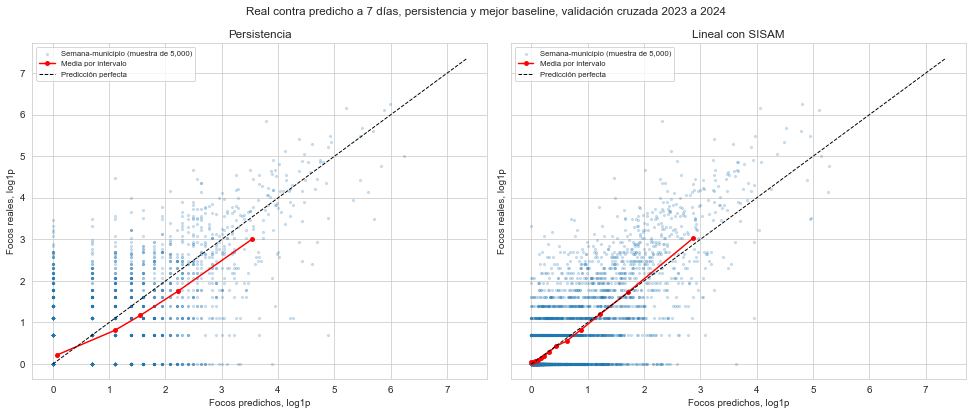

In [17]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
muestra_diag = {m: d.sample(5000, random_state=SEMILLA) for m, d in datos_diag.items()}
for eje, m in zip(ejes, MODELOS_DIAG):
    d, mu = datos_diag[m], muestra_diag[m]
    x, y = np.log1p(d["pred"]), np.log1p(d["real"])
    eje.scatter(np.log1p(mu["pred"]), np.log1p(mu["real"]), s=5, alpha=0.2, color="tab:blue", label="Semana-municipio (muestra de 5,000)")
    intervalos = pd.qcut(x, 15, duplicates="drop")
    medias = pd.DataFrame({"x": x, "y": y}).groupby(intervalos, observed=True).mean()
    eje.plot(medias["x"], medias["y"], color="red", marker="o", markersize=4, label="Media por intervalo")
    limite = max(x.max(), y.max())
    eje.plot([0, limite], [0, limite], color="black", linestyle="--", linewidth=1, label="Predicción perfecta")
    eje.set_title(ETIQUETA_MODELO[m])
    eje.set_xlabel("Focos predichos, log1p")
    eje.set_ylabel("Focos reales, log1p")
    eje.legend(fontsize=8, loc="upper left")
fig.suptitle("Real contra predicho a 7 días, persistencia y mejor baseline, validación cruzada 2023 a 2024")
plt.tight_layout()
plt.show()


**Figura 3.** Dispersión de los focos reales contra los predichos a 7 días (escala log1p) para la persistencia y el mejor baseline, con la diagonal de predicción perfecta y la media por intervalos. Muestra de 5,000 filas de la validación cruzada 2023 a 2024.


Error por rango de focos reales a 7 días (validación 2023 a 2024):
                       MAE                         filas                         sesgo             
modelo    Lineal con SISAM Persistencia Lineal con SISAM Persistencia Lineal con SISAM Persistencia
rango                                                                                              
0 focos              0.378        0.450       36,546.000   36,546.000            0.378        0.450
1 a 5                1.760        2.818       11,673.000   11,673.000           -0.322        0.613
6 a 20               6.727        8.808        4,394.000    4,394.000           -4.461        0.038
más de 20           49.062       43.061        2,230.000    2,230.000          -43.898      -11.167


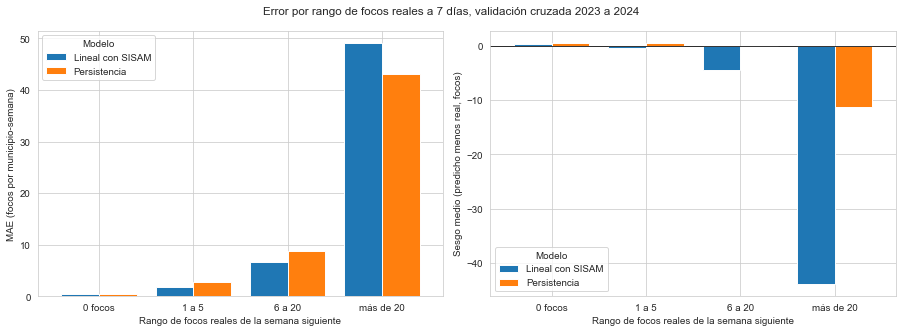

In [18]:
RANGOS = [-0.5, 0.5, 5.5, 20.5, np.inf]
ETIQUETAS_RANGO = ["0 focos", "1 a 5", "6 a 20", "más de 20"]
filas = []
for m, d in datos_diag.items():
    rango = pd.cut(d["real"], RANGOS, labels=ETIQUETAS_RANGO)
    error = d["pred"] - d["real"]
    t = pd.DataFrame({"rango": rango, "error": error, "error_abs": error.abs()}).groupby("rango", observed=True).agg(
        filas=("error", "size"), MAE=("error_abs", "mean"), sesgo=("error", "mean")).reset_index()
    t["modelo"] = ETIQUETA_MODELO[m]
    filas.append(t)
error_rango = pd.concat(filas, ignore_index=True)
print("Error por rango de focos reales a 7 días (validación 2023 a 2024):")
print(error_rango.pivot_table(index="rango", columns="modelo", values=["filas", "MAE", "sesgo"], observed=True).to_string(float_format=lambda v: f"{v:,.3f}"))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
for eje, metrica, etiqueta in [(ejes[0], "MAE", "MAE (focos por municipio-semana)"), (ejes[1], "sesgo", "Sesgo medio (predicho menos real, focos)")]:
    error_rango.pivot_table(index="rango", columns="modelo", values=metrica, observed=True).loc[ETIQUETAS_RANGO].plot(kind="bar", ax=eje, width=0.8)
    eje.set_xlabel("Rango de focos reales de la semana siguiente")
    eje.set_ylabel(etiqueta)
    eje.axhline(0, color="black", linewidth=0.8)
    eje.legend(title="Modelo")
    plt.setp(eje.get_xticklabels(), rotation=0)
fig.suptitle("Error por rango de focos reales a 7 días, validación cruzada 2023 a 2024")
plt.tight_layout()
plt.show()


**Figura 4.** MAE (izquierda) y sesgo medio (derecha) de la persistencia y del mejor baseline a 7 días, según el rango de focos reales de la semana siguiente. Predicciones de los 4 folds juntas, 2023 a 2024.


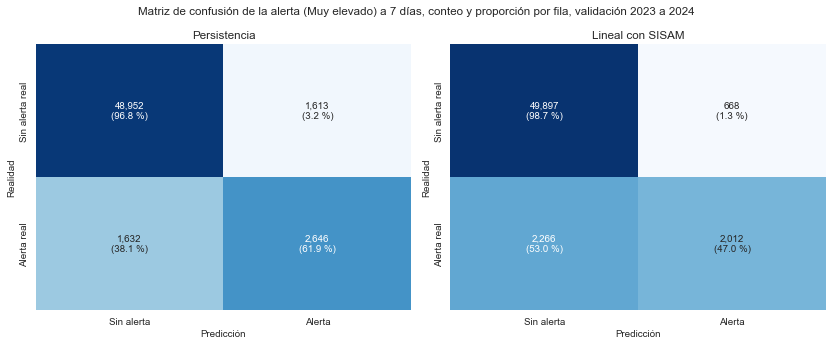

Matriz de la alerta con los 4 folds juntos (verdaderos negativos, falsas alarmas, no detectadas, verdaderos positivos):
Persistencia: VN 48,952 | FP 1,613 | FN 1,632 | VP 2,646 | recall 0.619 | precisión 0.621 | falsas alarmas 0.032
Lineal con SISAM: VN 49,897 | FP 668 | FN 2,266 | VP 2,012 | recall 0.470 | precisión 0.751 | falsas alarmas 0.013


In [19]:
def matriz_alerta(d):
    # matriz binaria: filas = alerta real (no, si), columnas = alerta predicha (no, si); alerta = focos sobre el p75 de la temporada
    umbral = np.where(d["objetivo_seca"].to_numpy() == 1, UMBRAL_SECA, UMBRAL_HUMEDA)
    real, pred = d["real"].to_numpy() > umbral, d["pred"].to_numpy() > umbral
    return np.array([[(~real & ~pred).sum(), (~real & pred).sum()], [(real & ~pred).sum(), (real & pred).sum()]])


fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for eje, m in zip(ejes, MODELOS_DIAG):
    conteos = matriz_alerta(datos_diag[m])
    proporciones = conteos / conteos.sum(axis=1, keepdims=True)
    etiquetas = np.array([[f"{conteos[i, j]:,}\n({proporciones[i, j] * 100:.1f} %)" for j in range(2)] for i in range(2)])
    sns.heatmap(proporciones, annot=etiquetas, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=eje,
                xticklabels=["Sin alerta", "Alerta"], yticklabels=["Sin alerta real", "Alerta real"])
    eje.set_title(ETIQUETA_MODELO[m])
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Realidad")
fig.suptitle("Matriz de confusión de la alerta (Muy elevado) a 7 días, conteo y proporción por fila, validación 2023 a 2024")
plt.tight_layout()
plt.show()

print("Matriz de la alerta con los 4 folds juntos (verdaderos negativos, falsas alarmas, no detectadas, verdaderos positivos):")
for m in MODELOS_DIAG:
    (vn, fp), (fn, vp) = matriz_alerta(datos_diag[m])
    print(f"{ETIQUETA_MODELO[m]}: VN {vn:,} | FP {fp:,} | FN {fn:,} | VP {vp:,} | recall {vp / (vp + fn):.3f} | precisión {vp / (vp + fp):.3f} | falsas alarmas {fp / (fp + vn):.3f}")


**Figura 5.** Matriz de confusión binaria de la alerta (nivel Muy elevado por temporada) para la persistencia y el mejor baseline, con el conteo y la proporción de cada fila real. Predicciones de los 4 folds juntas, 2023 a 2024.


### Hallazgos de esta etapa

**Qué se observa**
- El **66.6 %** de las filas de validación tiene 0 focos reales a 7 días.
- **Real contra predicho** (ver Figura 3): la media por intervalos de la Regresión Lineal sigue casi la diagonal, pero con mucha dispersión por encima de ella (los picos se subestiman). La de la persistencia queda por debajo de la diagonal en los valores altos.
- **Error por rango** (ver Figura 4): con 0 focos reales el MAE es **0.450** (persistencia) y **0.378** (lineal); con 1 a 5 focos, **2.818** y **1.760**; con 6 a 20, **8.808** y **6.727**; con más de 20, **43.061** y **49.062**. El sesgo con más de 20 focos es **-11.167** (persistencia) y **-43.898** (lineal), y con 6 a 20 focos la lineal tiene **-4.461**.
- **Alerta** (ver Figura 5, 4 folds juntos): la persistencia tiene **48,952** verdaderos negativos, **1,613** falsas alarmas, **1,632** alertas no detectadas y **2,646** aciertos (recall **0.619**, precisión **0.621**, falsas alarmas **0.032**). La lineal tiene **49,897**, **668**, **2,266** y **2,012** (recall **0.470**, precisión **0.751**, falsas alarmas **0.013**).

**Por qué importa**
- La Regresión Lineal gana en los rangos bajos y medios, pero pierde en el rango de más de 20 focos, donde subestima casi todo el valor real. Ahí está el error que más importa.
- La persistencia detecta más alertas (recall **0.619** frente a **0.470**) a costa de más falsas alarmas, mientras que la lineal es más precisa pero deja pasar más alertas.

**Qué implica para el modelado avanzado**
- Un modelo avanzado debe reducir el error en los rangos altos (más de 20 focos) y subir el recall de alerta sin pasar de las falsas alarmas del baseline.
- **Limitación:** las cifras de la alerta de esta sección agrupan los 4 folds, por eso difieren de los promedios por fold de la sección 5 (por ejemplo recall **0.579** de la persistencia).


## 6. Prueba 2025 (una sola vez)

Se ajusta cada modelo con **todo el entrenamiento** (2022-01-31 a 2024-12-02) y se evalúa **una sola vez** en 2025 (semanas 2025-01-06 a 2025-12-22), con las mismas métricas. El resultado queda en una tabla separada de la validación cruzada y las predicciones se guardan en `resultados/baseline_predicciones_2025.csv`. No se toma ninguna decisión con estos números.


In [20]:
idx_prueba = panel.index[panel["particion"].eq("prueba")]
for frente in ["f1_7d", "f1_30d", "f2"]:
    evaluar_persistencia(frente, idx_prueba, "prueba_2025", 0)
for frente in ["f1_7d", "f1_30d"]:
    for nombre in MODELOS_F1:
        for sisam in ["con", "sin"]:
            ajustar_y_evaluar(frente, nombre, sisam, idx_entreno_total, idx_prueba, "prueba_2025", 0)
for nombre in MODELOS_F2:
    for sisam in ["con", "sin"]:
        ajustar_y_evaluar("f2", nombre, sisam, idx_entreno_total, idx_prueba, "prueba_2025", 0)
resultados = pd.DataFrame(REGISTROS)

filas_2025 = {"f1_7d": int((VALIDO["f1_7d"] & panel["particion"].eq("prueba")).sum()), "f1_30d": int((VALIDO["f1_30d"] & panel["particion"].eq("prueba")).sum()),
              "f2": int((VALIDO["f2"] & panel["particion"].eq("prueba")).sum())}
print("Filas evaluadas en 2025:", filas_2025)
focos_anio = panel.groupby(panel["semana"].dt.year)["num_incendios_crudo"].sum()
print(f"\nFocos totales por año: {focos_anio.to_dict()}")
print(f"Cambio de nivel 2025 frente a 2024: {(focos_anio[2025] / focos_anio[2024] - 1) * 100:.1f} %")
print("Media de y_7d (focos reales por municipio-semana): entrenamiento", f"{panel.loc[VALIDO['f1_7d'] & es_entrenamiento, 'y_7d'].mean():.3f}",
      "| prueba 2025", f"{panel.loc[VALIDO['f1_7d'] & panel['particion'].eq('prueba'), 'y_7d'].mean():.3f}")

r25 = resultados[resultados["evaluacion"] == "prueba_2025"]
for frente, metricas in [("f1_7d", ["MAE", "RMSE", "MAE_con_focos", "R2_log1p", "sesgo", "recall_alerta", "precision_alerta", "tasa_falsas_alarmas"]),
                         ("f1_30d", ["MAE", "RMSE", "MAE_con_focos", "R2_log1p", "sesgo"])]:
    t = r25[(r25["frente"] == frente) & r25["metrica"].isin(metricas)].pivot_table(index=["modelo", "sisam"], columns="metrica", values="valor")[metricas]
    print(f"\nPrueba 2025, {frente}:")
    mostrar(t, 3)
for subconjunto in ["con_clase_t", "todas"]:
    t = r25[(r25["frente"] == "f2") & (r25["subconjunto"] == subconjunto) & r25["metrica"].isin(["accuracy", "F1_macro", "recall_critico", "error_ordinal"])]
    print(f"\nPrueba 2025, Frente 2 (subconjunto {subconjunto}):")
    mostrar(t.pivot_table(index=["modelo", "sisam"], columns="metrica", values="valor")[["accuracy", "F1_macro", "recall_critico", "error_ordinal"]], 3)


Filas evaluadas en 2025: {'f1_7d': 27693, 'f1_30d': 27693, 'f2': 6601}

Focos totales por año: {2022: 115022, 2023: 98620, 2024: 140656, 2025: 43525, 2026: 44769}
Cambio de nivel 2025 frente a 2024: -69.1 %
Media de y_7d (focos reales por municipio-semana): entrenamiento 4.332 | prueba 2025 1.566

Prueba 2025, f1_7d:
metrica                  MAE  RMSE  MAE_con_focos  R2_log1p  sesgo  recall_alerta  precision_alerta  tasa_falsas_alarmas
modelo       sisam                                                                                                      
arbol        con       1.382 5.611          4.537     0.502 -0.395          0.374             0.614                0.010
             sin       1.376 5.475          4.508     0.505 -0.397          0.371             0.620                0.010
lineal       con       1.295 4.849          4.251     0.533 -0.570          0.361             0.671                0.008
             sin       1.299 4.823          4.236     0.532 -0.549          

In [21]:
# cambio de desempeno frente a la validacion cruzada (promedio de los 4 folds)
def comparar_con_cv(frente, subconjunto, metrica):
    base = resultados[(resultados["frente"] == frente) & (resultados["subconjunto"] == subconjunto) & (resultados["metrica"] == metrica)]
    cv = base[base["evaluacion"] == "cv_fold"].groupby(["modelo", "sisam"])["valor"].mean().reset_index().rename(columns={"valor": "validacion_cruzada"})
    p25 = base[base["evaluacion"] == "prueba_2025"].groupby(["modelo", "sisam"])["valor"].mean().reset_index().rename(columns={"valor": "prueba_2025"})
    t = cv.merge(p25, on=["modelo", "sisam"]).set_index(["modelo", "sisam"])
    t["cambio_pct"] = (t["prueba_2025"] / t["validacion_cruzada"] - 1) * 100
    return t


print("Frente 1 a 7 días, MAE: validación cruzada frente a prueba 2025")
mostrar(comparar_con_cv("f1_7d", "todas", "MAE"), 3)
print("\nFrente 1 a 30 días, MAE:")
mostrar(comparar_con_cv("f1_30d", "todas", "MAE"), 3)
print("\nFrente 2 (con clase de la semana actual), F1 macro:")
mostrar(comparar_con_cv("f2", "con_clase_t", "F1_macro"), 3)


Frente 1 a 7 días, MAE: validación cruzada frente a prueba 2025
                        validacion_cruzada  prueba_2025  cambio_pct
modelo       sisam                                                 
arbol        con                     3.383        1.382     -59.137
             sin                     3.357        1.376     -59.002
lineal       con                     3.274        1.295     -60.444
             sin                     3.281        1.299     -60.414
persistencia no aplica               3.461        1.451     -58.063

Frente 1 a 30 días, MAE:
                        validacion_cruzada  prueba_2025  cambio_pct
modelo       sisam                                                 
arbol        con                    12.444        5.118     -58.876
             sin                    12.271        5.025     -59.051
lineal       con                    12.451        4.655     -62.613
             sin                    12.471        4.651     -62.706
persistencia no aplica    

In [22]:
p = pd.concat(PREDICCIONES, ignore_index=True)
p25 = p[(p["evaluacion"] == "prueba_2025") & (p["subconjunto"].isin(["todas"]) | (p["modelo"] == "persistencia"))].copy()
# una fila por modelo, frente y semana-municipio (el Frente 2 se guarda con todas las filas; la persistencia, solo donde esta definida)
p25 = p25.drop_duplicates(["idx", "frente", "modelo", "sisam"])
etiqueta = np.where(p25["sisam"] == "no aplica", p25["modelo"], p25["modelo"] + "_" + p25["sisam"] + "_sisam")
salida = pd.DataFrame({"semana": panel.loc[p25["idx"], "semana"].dt.strftime("%Y-%m-%d").to_numpy(),
                       "municipio_norm": panel.loc[p25["idx"], "municipio_norm"].to_numpy(), "uf": panel.loc[p25["idx"], "uf"].to_numpy(),
                       "frente": p25["frente"].to_numpy(), "real": p25["real"].round(3).to_numpy(), "predicho": p25["pred"].round(3).to_numpy(),
                       "modelo": etiqueta})
RUTA_PRED = DIR_RESULTADOS / "baseline_predicciones_2025.csv"
salida.to_csv(RUTA_PRED, index=False, encoding="utf-8")
print("Guardado:", RUTA_PRED.relative_to(BASE), salida.shape, f"({RUTA_PRED.stat().st_size / 1e6:,.1f} MB)")
print("Filas por frente y modelo:")
print(salida.groupby(["frente", "modelo"]).size().unstack("frente").to_string())
assert salida["semana"].min() >= "2025-01-06" and salida["semana"].max() <= "2025-12-22", "Las predicciones deben ser solo de 2025"


Guardado: resultados\baseline_predicciones_2025.csv (307247, 7) (18.4 MB)
Filas por frente y modelo:
frente                       f1_30d    f1_7d      f2
modelo                                              
arbol_balanceado_con_sisam      NaN      NaN  6601.0
arbol_balanceado_sin_sisam      NaN      NaN  6601.0
arbol_con_sisam             27693.0  27693.0  6601.0
arbol_sin_sisam             27693.0  27693.0  6601.0
lineal_con_sisam            27693.0  27693.0     NaN
lineal_sin_sisam            27693.0  27693.0     NaN
persistencia                27693.0  27693.0  3913.0


### Hallazgos de esta etapa

**Qué se observa**
- Con el ajuste final y una sola evaluación en 2025 (**27,693** filas del Frente 1 y **6,601** del Frente 2), el MAE a 7 días es **1.295** (lineal con SISAM), **1.299** (lineal sin SISAM), **1.376** (árbol sin SISAM), **1.382** (árbol con SISAM) y **1.451** (persistencia). A 30 días: **4.651**, **4.655**, **5.025**, **5.118** y **5.802**.
- El MAE cae cerca de 60 % frente a la validación cruzada en todos los modelos (por ejemplo **-60.444 %** la lineal con SISAM y **-58.063 %** la persistencia). Los focos totales de 2025 son **-69.1 %** frente a 2024 y la media de `y_7d` pasa de **4.332** a **1.566**.
- El KPI de alerta a 7 días en 2025: la persistencia tiene recall **0.510**, precisión **0.518** y falsas alarmas **0.021**; la lineal con SISAM **0.361**, **0.671** y **0.008**.
- En el Frente 2 (filas con clase de la semana actual), el accuracy de la persistencia baja de **0.686** a **0.582**, y su F1 macro es **0.562**. Los árboles dan F1 macro de **0.541** a **0.562**, prácticamente empatados con la persistencia.

**Por qué importa**
- La caída del MAE no es una mejora de los modelos: es el cambio de nivel de 2025. La comparación útil es la relativa entre modelos y persistencia (por ejemplo, R² en `log1p` de **0.533** frente a **0.357**).
- La ventaja de la Regresión Lineal sobre la persistencia se mantiene en 2025 a 7 y a 30 días. En 30 días la lineal supera al árbol (**4.655** frente a **5.025** del árbol sin SISAM), al revés de lo visto en validación.

**Qué implica para el modelado avanzado**
- **Limitación:** el desempeño de 2025 no es comparable en valor absoluto con el de la validación cruzada por el cambio de nivel de **-69.1 %** en los focos. Los criterios de éxito se expresan como reducción relativa frente al mejor baseline.


## 7. Tabla comparativa y criterios de éxito

Tabla única por frente con la persistencia y los modelos base, en validación cruzada (promedio y desviación estándar entre folds) y en 2025, con y sin SISAM. Se guarda en `resultados/baseline_metricas.csv` en formato largo. Después se proponen **criterios de éxito** para el modelado avanzado y **umbrales provisionales** para los KPI de control, derivados de estos números. Las cifras son propuestas para validar con el equipo.


In [23]:
def tabla_comparativa(frente, subconjunto, metricas):
    cv = resumen_cv(frente, subconjunto, metricas)
    t = como_texto(cv)
    t.columns = [f"{m} (CV)" for m in t.columns]
    p = resultados[(resultados["frente"] == frente) & (resultados["evaluacion"] == "prueba_2025") & (resultados["subconjunto"] == subconjunto)
                   & resultados["metrica"].isin(metricas)].pivot_table(index=["modelo", "sisam"], columns="metrica", values="valor")[metricas]
    p.columns = [f"{m} (2025)" for m in p.columns]
    return t.join(p.map(lambda v: f"{v:.3f}"))


M_F1 = ["MAE", "RMSE", "MAE_con_focos", "R2_log1p", "sesgo"]
print("FRENTE 1 A 7 DÍAS (CV: promedio +/- desviación entre folds; 2025: una sola evaluación)")
print(tabla_comparativa("f1_7d", "todas", M_F1).to_string())
print("\nFRENTE 1 A 30 DÍAS")
print(tabla_comparativa("f1_30d", "todas", M_F1).to_string())
print("\nFRENTE 2 (filas con clase de la semana actual)")
print(tabla_comparativa("f2", "con_clase_t", ["accuracy", "F1_macro", "recall_critico", "error_ordinal"]).to_string())
print("\nFRENTE 2 (todas las filas con valido_f2; la persistencia no está definida)")
print(tabla_comparativa("f2", "todas", ["accuracy", "F1_macro", "recall_critico", "error_ordinal"]).to_string())


FRENTE 1 A 7 DÍAS (CV: promedio +/- desviación entre folds; 2025: una sola evaluación)
                               MAE (CV)          RMSE (CV) MAE_con_focos (CV)    R2_log1p (CV)        sesgo (CV) MAE (2025) RMSE (2025) MAE_con_focos (2025) R2_log1p (2025) sesgo (2025)
modelo       sisam                                                                                                                                                                       
arbol        con        3.383 +/- 3.115  15.093 +/- 13.672    7.239 +/- 4.407  0.490 +/- 0.105  -1.308 +/- 1.349      1.382       5.611                4.537           0.502       -0.395
             sin        3.357 +/- 3.098  14.980 +/- 13.690    7.169 +/- 4.406  0.493 +/- 0.103  -1.286 +/- 1.296      1.376       5.475                4.508           0.505       -0.397
lineal       con        3.274 +/- 3.134  15.376 +/- 15.049    7.019 +/- 4.541  0.561 +/- 0.073  -2.025 +/- 2.010      1.295       4.849                4.251           0.

In [24]:
# archivo largo con todas las metricas: promedio y desviacion entre folds, y prueba 2025
cv = resultados[resultados["evaluacion"] == "cv_fold"].groupby(["frente", "modelo", "sisam", "subconjunto", "metrica"])["valor"].agg(["mean", "std"]).reset_index()
cv_largo = pd.concat([cv.rename(columns={"mean": "valor"}).assign(evaluacion="cv_promedio").drop(columns="std"),
                      cv.rename(columns={"std": "valor"}).assign(evaluacion="cv_desviacion").drop(columns="mean")])
otros = resultados[resultados["evaluacion"].isin(["prueba_2025", "entrenamiento_completo"])].drop(columns="fold")
largo = pd.concat([cv_largo, otros], ignore_index=True)[["frente", "modelo", "sisam", "evaluacion", "subconjunto", "metrica", "valor"]]
RUTA_METRICAS = DIR_RESULTADOS / "baseline_metricas.csv"
largo.to_csv(RUTA_METRICAS, index=False, encoding="utf-8", float_format="%.6g")
print("Guardado:", RUTA_METRICAS.relative_to(BASE), largo.shape, f"({RUTA_METRICAS.stat().st_size / 1e3:,.1f} KB)")
print("Evaluaciones:", largo["evaluacion"].value_counts().to_dict())


Guardado: resultados\baseline_metricas.csv (560, 7) (34.8 KB)
Evaluaciones: {'cv_promedio': 178, 'cv_desviacion': 178, 'prueba_2025': 178, 'entrenamiento_completo': 26}


In [25]:
def media_std(frente, subconjunto, metrica):
    t = resultados[(resultados["frente"] == frente) & (resultados["evaluacion"] == "cv_fold") & (resultados["subconjunto"] == subconjunto)
                   & (resultados["metrica"] == metrica)].groupby(["modelo", "sisam"])["valor"].agg(["mean", "std"])
    return t


def valor_2025(frente, subconjunto, metrica, modelo, sisam):
    r = resultados[(resultados["frente"] == frente) & (resultados["evaluacion"] == "prueba_2025") & (resultados["subconjunto"] == subconjunto)
                   & (resultados["metrica"] == metrica) & (resultados["modelo"] == modelo) & (resultados["sisam"] == sisam)]
    return float(r["valor"].iloc[0])


REDUCCION_MINIMA_PCT = 10.0     # mejora minima exigida al modelado avanzado frente al mejor baseline
FOLDS_MINIMOS = 3               # y debe mejorar al mejor baseline en al menos 3 de los 4 folds
criterios = []
for frente, nombre in [("f1_7d", "Frente 1 a 7 días"), ("f1_30d", "Frente 1 a 30 días")]:
    t = media_std(frente, "todas", "MAE")
    mejor = t["mean"].idxmin()
    por_fold = mae_fold[mae_fold["frente"] == frente].pivot_table(index="fold", columns=["modelo", "sisam"], values="valor")
    mejora_vs_persistencia = (1 - por_fold[mejor] / por_fold[("persistencia", "no aplica")]) * 100
    criterios.append({"frente": nombre, "mejor_baseline": ETIQUETA_MODELO[mejor], "MAE_cv_baseline": t.loc[mejor, "mean"],
                      "mejora_pct_sobre_persistencia": mejora_vs_persistencia.mean(),
                      "folds_donde_supera_persistencia": int((mejora_vs_persistencia > 0).sum()),
                      "reduccion_minima_pct": REDUCCION_MINIMA_PCT, "MAE_objetivo_cv": t.loc[mejor, "mean"] * (1 - REDUCCION_MINIMA_PCT / 100),
                      "MAE_2025_baseline": valor_2025(frente, "todas", "MAE", *mejor),
                      "MAE_objetivo_2025": valor_2025(frente, "todas", "MAE", *mejor) * (1 - REDUCCION_MINIMA_PCT / 100)})
    print(f"{nombre}: mejora del mejor baseline sobre la persistencia, por fold (%):", [round(v, 1) for v in mejora_vs_persistencia])
tabla_criterios_f1 = pd.DataFrame(criterios).set_index("frente")
print("\nCriterio de éxito del Frente 1: reducir al menos 10 % el MAE del mejor baseline, y mejorarlo en al menos 3 de los 4 folds")
print(tabla_criterios_f1.T.to_string(float_format=lambda v: f"{v:,.3f}"))
MEJOR_F1_7D = media_std("f1_7d", "todas", "MAE")["mean"].idxmin()
MEJOR_F1_30D = media_std("f1_30d", "todas", "MAE")["mean"].idxmin()


Frente 1 a 7 días: mejora del mejor baseline sobre la persistencia, por fold (%): [7.3, 12.0, 18.2, -1.6]
Frente 1 a 30 días: mejora del mejor baseline sobre la persistencia, por fold (%): [0.7, 15.5, 15.6, 19.1]

Criterio de éxito del Frente 1: reducir al menos 10 % el MAE del mejor baseline, y mejorarlo en al menos 3 de los 4 folds
frente                          Frente 1 a 7 días Frente 1 a 30 días
mejor_baseline                   Lineal con SISAM    Árbol sin SISAM
MAE_cv_baseline                             3.274             12.271
mejora_pct_sobre_persistencia               8.972             12.743
folds_donde_supera_persistencia                 3                  4
reduccion_minima_pct                       10.000             10.000
MAE_objetivo_cv                             2.946             11.044
MAE_2025_baseline                           1.295              5.025
MAE_objetivo_2025                           1.165              4.523


In [26]:
filas = []
for subconjunto in ["con_clase_t"]:
    f1m, rc = media_std("f2", subconjunto, "F1_macro"), media_std("f2", subconjunto, "recall_critico")
    mejor = f1m["mean"].idxmax()
    margen_f1 = min(max(0.02, float(np.ceil(f1m.loc[mejor, "std"] * 100) / 100)), 0.10)
    margen_rc = min(max(0.02, float(np.ceil(rc.loc[mejor, "std"] * 100) / 100)), 0.10)
    filas.append({"mejor_baseline": ETIQUETA_MODELO[mejor], "F1_macro_baseline": f1m.loc[mejor, "mean"], "desv_F1": f1m.loc[mejor, "std"],
                  "F1_macro_objetivo": f1m.loc[mejor, "mean"] + margen_f1, "recall_critico_baseline": rc.loc[mejor, "mean"], "desv_recall": rc.loc[mejor, "std"],
                  "recall_critico_objetivo": rc.loc[mejor, "mean"] + margen_rc})
MEJOR_F2 = f1m["mean"].idxmax()
tabla_criterios_f2 = pd.DataFrame(filas, index=["Frente 2"])
print("Criterio de éxito del Frente 2: superar al mejor baseline por una desviación entre folds, redondeada hacia arriba a 0.01, con mínimo 0.02 y máximo 0.10")
print(tabla_criterios_f2.T.to_string(float_format=lambda v: f"{v:,.3f}"))
print("\nReferencia 2025 del mejor baseline del Frente 2: F1 macro", f"{valor_2025('f2', 'con_clase_t', 'F1_macro', *MEJOR_F2):.3f}",
      "| recall de Crítico", f"{valor_2025('f2', 'con_clase_t', 'recall_critico', *MEJOR_F2):.3f}")


Criterio de éxito del Frente 2: superar al mejor baseline por una desviación entre folds, redondeada hacia arriba a 0.01, con mínimo 0.02 y máximo 0.10
                             Frente 2
mejor_baseline           Persistencia
F1_macro_baseline               0.555
desv_F1                         0.060
F1_macro_objetivo               0.615
recall_critico_baseline         0.545
desv_recall                     0.261
recall_critico_objetivo         0.645

Referencia 2025 del mejor baseline del Frente 2: F1 macro 0.562 | recall de Crítico 0.635


In [27]:
# umbrales provisionales de los KPI de control, a partir de las metricas por fold del mejor baseline a 7 dias
rec, pre, fal = (media_std("f1_7d", "todas", m) for m in ["recall_alerta", "precision_alerta", "tasa_falsas_alarmas"])
mae = media_std("f1_7d", "todas", "MAE")
p_mejor = predicciones_cv("f1_7d", "todas")
p_mejor = p_mejor[(p_mejor["modelo"] == MEJOR_F1_7D[0]) & (p_mejor["sisam"] == MEJOR_F1_7D[1])].copy()
p_mejor["semana"] = panel.loc[p_mejor["idx"], "semana"].to_numpy()
p_mejor["error_abs"] = (p_mejor["pred"] - p_mejor["real"]).abs()
mae_semanal = p_mejor.groupby("semana")["error_abs"].mean().sort_index()
mae_movil = mae_semanal.rolling(4).mean().dropna()

umbrales = pd.DataFrame({
    "baseline_media": [mae.loc[MEJOR_F1_7D, "mean"], rec.loc[MEJOR_F1_7D, "mean"], fal.loc[MEJOR_F1_7D, "mean"]],
    "desv_entre_folds": [mae.loc[MEJOR_F1_7D, "std"], rec.loc[MEJOR_F1_7D, "std"], fal.loc[MEJOR_F1_7D, "std"]],
}, index=["MAE móvil de 4 semanas (máximo)", "Recall de alerta (mínimo)", "Tasa de falsas alarmas (máximo)"])
umbrales["umbral_provisional"] = [umbrales.iloc[0, 0] + umbrales.iloc[0, 1], max(0.0, umbrales.iloc[1, 0] - umbrales.iloc[1, 1]), umbrales.iloc[2, 0] + umbrales.iloc[2, 1]]
print(f"Mejor baseline a 7 días: {ETIQUETA_MODELO[MEJOR_F1_7D]}")
print("Umbrales provisionales de control (media del fold +/- 1 desviación entre folds):")
print(umbrales.to_string(float_format=lambda v: f"{v:,.3f}"))
print(f"\nMAE móvil de 4 semanas del mejor baseline en la validación 2023-2024: mediana {mae_movil.median():.3f} | percentil 90 {mae_movil.quantile(0.9):.3f} | máximo {mae_movil.max():.3f}")
print(f"Semanas de validación con MAE móvil por encima del umbral: {(mae_movil > umbrales.iloc[0, 2]).mean() * 100:.1f} %")


Mejor baseline a 7 días: Lineal con SISAM
Umbrales provisionales de control (media del fold +/- 1 desviación entre folds):
                                 baseline_media  desv_entre_folds  umbral_provisional
MAE móvil de 4 semanas (máximo)           3.274             3.134               6.408
Recall de alerta (mínimo)                 0.436             0.076               0.360
Tasa de falsas alarmas (máximo)           0.014             0.012               0.026

MAE móvil de 4 semanas del mejor baseline en la validación 2023-2024: mediana 1.306 | percentil 90 7.612 | máximo 15.412
Semanas de validación con MAE móvil por encima del umbral: 16.3 %


### Valores iniciales de referencia

Para cada métrica de la sección 2 se toma el **mejor baseline** (persistencia o modelo base) según su promedio en la validación cruzada, y se muestran su promedio y desviación entre folds y su valor en 2025. La elección se hace **solo con la validación**; 2025 se informa para ese mismo modelo y no interviene en la elección. Para el Frente 2 se usa el subconjunto con clase de la semana actual, donde la persistencia está definida. Este cuadro es el que va al informe como "métricas iniciales".


In [28]:
SENTIDO = {"MAE": "menor", "RMSE": "menor", "MAE_con_focos": "menor", "sesgo": "cercano a 0", "R2_log1p": "mayor",
           "accuracy": "mayor", "F1_macro": "mayor", "error_ordinal": "menor", "recall_alerta": "mayor", "precision_alerta": "mayor",
           "tasa_falsas_alarmas": "menor"}
for clase in CLASES:
    SENTIDO[f"F1_{clase}"] = "mayor"
    SENTIDO[f"recall_{clase}"] = "mayor"
NOMBRE_METRICA = {"MAE": "MAE (focos)", "RMSE": "RMSE (focos)", "MAE_con_focos": "MAE solo con focos reales", "sesgo": "Sesgo medio (focos)",
                  "R2_log1p": "R2 en log1p", "accuracy": "Accuracy", "F1_macro": "F1 macro", "error_ordinal": "Error ordinal medio",
                  "recall_alerta": "Recall de alerta", "precision_alerta": "Precisión de alerta", "tasa_falsas_alarmas": "Tasa de falsas alarmas"}
for clase in CLASES:
    NOMBRE_METRICA[f"F1_{clase}"] = f"F1 {clase}"
    NOMBRE_METRICA[f"recall_{clase}"] = f"Recall {clase}" + (" (recall de Crítico)" if clase == "Crítico" else "")

ORDEN = [("f1_7d", "todas", "Frente 1 a 7 días", ["MAE", "RMSE", "MAE_con_focos", "sesgo", "R2_log1p"]),
         ("f1_30d", "todas", "Frente 1 a 30 días", ["MAE", "RMSE", "MAE_con_focos", "sesgo", "R2_log1p"]),
         ("f2", "con_clase_t", "Frente 2", ["accuracy", "F1_macro"] + [f"F1_{c}" for c in CLASES] + [f"recall_{c}" for c in CLASES] + ["error_ordinal"]),
         ("f1_7d", "todas", "KPI de alerta (7 días)", ["recall_alerta", "precision_alerta", "tasa_falsas_alarmas"])]
filas = []
for frente, subconjunto, titulo, metricas in ORDEN:
    for metrica in metricas:
        t = media_std(frente, subconjunto, metrica)
        sentido = SENTIDO[metrica]
        mejor = t["mean"].abs().idxmin() if sentido == "cercano a 0" else (t["mean"].idxmin() if sentido == "menor" else t["mean"].idxmax())
        filas.append({"frente": titulo, "metrica": NOMBRE_METRICA[metrica], "mejor_es": sentido, "mejor_baseline": ETIQUETA_MODELO[mejor],
                      "validacion_media": t.loc[mejor, "mean"], "validacion_desv": t.loc[mejor, "std"],
                      "prueba_2025": valor_2025(frente, subconjunto, metrica, *mejor), "clave": metrica})
valores_iniciales = pd.DataFrame(filas)
print("VALORES INICIALES DE REFERENCIA (mejor baseline por métrica; elegido solo con la validación 2023-2024)")
print(valores_iniciales.drop(columns="clave").to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
RUTA_INICIALES = DIR_RESULTADOS / "baseline_valores_iniciales.csv"
valores_iniciales.to_csv(RUTA_INICIALES, index=False, encoding="utf-8", float_format="%.6g")
print("\nGuardado:", RUTA_INICIALES.relative_to(BASE), valores_iniciales.shape)


VALORES INICIALES DE REFERENCIA (mejor baseline por métrica; elegido solo con la validación 2023-2024)

                frente                            metrica    mejor_es             mejor_baseline  validacion_media  validacion_desv  prueba_2025
     Frente 1 a 7 días                        MAE (focos)       menor           Lineal con SISAM             3.274            3.134        1.295
     Frente 1 a 7 días                       RMSE (focos)       menor               Persistencia            14.205           11.899        5.291
     Frente 1 a 7 días          MAE solo con focos reales       menor           Lineal sin SISAM             7.015            4.634        4.236
     Frente 1 a 7 días                Sesgo medio (focos) cercano a 0               Persistencia            -0.022            0.025       -0.029
     Frente 1 a 7 días                        R2 en log1p       mayor           Lineal sin SISAM             0.562            0.076        0.532
    Frente 1 a 30 días                        MAE (focos)       menor            Árbol sin SISAM            12.271           11.13

### Hallazgos de esta etapa

**Qué se observa**
- **Frente 1 a 7 días:** el mejor baseline es la Regresión Lineal con SISAM (MAE **3.274** en validación y **1.295** en 2025). Mejora a la persistencia en promedio **8.972 %** y la supera en **3** de 4 folds (**7.3 %**, **12.0 %**, **18.2 %** y **-1.6 %**).
- **Frente 1 a 30 días:** el mejor baseline es el árbol sin SISAM (MAE **12.271** y **5.025** en 2025). Mejora a la persistencia en **12.743 %** y la supera en **4** de 4 folds.
- **Frente 2:** el mejor baseline es la persistencia, con F1 macro **0.555** (desviación **0.060**) y recall de Crítico **0.545** (desviación **0.261**). En 2025 da **0.562** y **0.635**.
- Para el KPI de alerta a 7 días, el mejor baseline tiene recall **0.436** (desviación **0.076**) y tasa de falsas alarmas **0.014** (desviación **0.012**). El MAE móvil de 4 semanas en la validación tiene mediana **1.306**, percentil 90 de **7.612** y máximo **15.412**.

- **Valores iniciales de referencia** (mejor baseline por métrica, validación y 2025): MAE a 7 días **3.274** (lineal con SISAM; **1.295** en 2025), RMSE **14.205** y sesgo **-0.022** (persistencia; **5.291** y **-0.029** en 2025), MAE solo con focos reales **7.015** (lineal sin SISAM) y R² en `log1p` **0.562**. A 30 días: MAE **12.271** y RMSE **52.938** (árbol sin SISAM; **5.025** y **21.429** en 2025). En el Frente 2: accuracy **0.686**, F1 macro **0.555**, recall de Crítico **0.545** y error ordinal **0.393** (persistencia; **0.582**, **0.562**, **0.635** y **0.527** en 2025). Alerta: recall **0.579** (persistencia), precisión **0.743** y falsas alarmas **0.014** (lineal con SISAM).

**Por qué se decidió así**
- Ningún modelo gana todas las métricas: la persistencia gana en RMSE, sesgo y en todo el Frente 2, y la lineal gana en MAE y en precisión de alerta. Por eso el cuadro de valores iniciales reúne el mejor de cada métrica.
- **Criterio del Frente 1:** reducir **10 %** el MAE del mejor baseline y mejorarlo en al menos **3** de 4 folds. El 10 % es un poco más que lo que el mejor baseline mejora a la persistencia (**8.972 %** a 7 días y **12.743 %** a 30 días), así que exige un avance real y no ruido.
- **Criterio del Frente 2:** superar al mejor baseline por una desviación entre folds, redondeada hacia arriba, con mínimo 0.02 y máximo 0.10. La desviación del recall de Crítico (**0.261**) es muy ancha, por eso se limita a 0.10.
- **Umbrales de control:** se toman a una desviación entre folds de la media del mejor baseline.

**Qué implica para el modelado avanzado (propuestas para validar)**
- El cuadro de valores iniciales (también guardado en `resultados/baseline_valores_iniciales.csv`) es el que va al informe como métricas iniciales.
- **Frente 1 a 7 días:** MAE de validación igual o menor que **2.946** (y **1.165** en 2025). **A 30 días:** **11.044** (y **4.523** en 2025).
- **Frente 2:** F1 macro igual o mayor que **0.615** y recall de Crítico igual o mayor que **0.645**.
- **KPI de control provisionales:** MAE móvil de 4 semanas por debajo de **6.408** (se supera en **16.3 %** de las semanas de validación), recall de alerta de al menos **0.360** y tasa de falsas alarmas de a lo sumo **0.026**.
- **Limitación:** son umbrales provisionales basados en 4 folds con mucha dispersión. La persistencia tiene más recall de alerta (**0.579**) pero más falsas alarmas (**0.033**), por lo que el punto de operación debe fijarse con el costo de cada error.


## 8. Análisis de errores del mejor baseline

Con el **mejor baseline a 7 días** (el de menor MAE promedio en la validación cruzada) y las predicciones de los 4 folds juntas (2023 a 2024), se calcula el error por estado y por temporada (de la semana objetivo), los 10 municipios con mayor error absoluto acumulado y la concentración del error. No se usa 2025 para este análisis.


In [29]:
p_mejor["uf"] = panel.loc[p_mejor["idx"], "uf"].to_numpy()
p_mejor["municipio_norm"] = panel.loc[p_mejor["idx"], "municipio_norm"].to_numpy()
p_mejor["temporada"] = np.where(panel.loc[p_mejor["idx"], "objetivo_seca"].to_numpy() == 1, "seca", "humeda")
p_mejor["sesgo"] = p_mejor["pred"] - p_mejor["real"]
total_error = p_mejor["error_abs"].sum()

por_uf = p_mejor.groupby("uf").agg(filas=("idx", "size"), focos_reales=("real", "sum"), MAE=("error_abs", "mean"), sesgo=("sesgo", "mean"), error_total=("error_abs", "sum"))
por_uf["aporte_error_pct"] = por_uf["error_total"] / total_error * 100
por_uf = por_uf.sort_values("error_total", ascending=False)
print(f"Error por estado (mejor baseline a 7 días: {ETIQUETA_MODELO[MEJOR_F1_7D]}, validación 2023 a 2024):")
mostrar(por_uf.drop(columns="error_total"), 3)

por_temporada = p_mejor.groupby("temporada").agg(filas=("idx", "size"), MAE=("error_abs", "mean"), sesgo=("sesgo", "mean"), error_total=("error_abs", "sum"))
por_temporada["aporte_error_pct"] = por_temporada["error_total"] / total_error * 100
print("\nError por temporada de la semana objetivo:")
mostrar(por_temporada.drop(columns="error_total"), 3)


Error por estado (mejor baseline a 7 días: Lineal con SISAM, validación 2023 a 2024):
    filas  focos_reales   MAE  sesgo  aporte_error_pct
uf                                                    
PA  14544    96,394.000 4.719 -3.284            39.601
AM   6262    45,081.000 4.940 -3.242            17.848
MT   9090    37,951.000 3.228 -1.586            16.929
RO   5252    18,080.000 2.543 -1.465             7.706
AC   2222    15,219.000 4.690 -3.038             6.013
MA  10807    10,294.000 0.844 -0.346             5.264
RR   1515     7,925.000 4.437 -2.818             3.879
AP   1616     4,532.000 2.086 -1.335             1.945
TO   3535     1,087.000 0.400 -0.100             0.817

Error por temporada de la semana objetivo:
           filas   MAE  sesgo  aporte_error_pct
temporada                                      
humeda     30951 0.811 -0.320            14.489
seca       23892 6.203 -4.082            85.511


In [30]:
top_municipios = (p_mejor.groupby(["municipio_norm", "uf"]).agg(error_total=("error_abs", "sum"), focos_reales=("real", "sum"), MAE=("error_abs", "mean"))
                  .sort_values("error_total", ascending=False).head(10))
top_municipios["aporte_error_pct"] = top_municipios["error_total"] / total_error * 100
print("10 municipios con mayor error absoluto acumulado:")
mostrar(top_municipios, 2)

n_filas = len(p_mejor)
orden_error = p_mejor["error_abs"].sort_values(ascending=False)
n_municipios = p_mejor.groupby(["municipio_norm", "uf"]).ngroups
print(f"\nLos 10 municipios principales aportan {top_municipios['aporte_error_pct'].sum():.1f} % del error absoluto (de {n_municipios} municipios).")
print(f"El 1 % de las filas con mayor error ({int(n_filas * 0.01):,} filas) aporta {orden_error.head(int(n_filas * 0.01)).sum() / total_error * 100:.1f} % del error absoluto.")
print(f"El 10 % de las filas con mayor error aporta {orden_error.head(int(n_filas * 0.10)).sum() / total_error * 100:.1f} % del error absoluto.")


10 municipios con mayor error absoluto acumulado:
                       error_total  focos_reales   MAE  aporte_error_pct
municipio_norm     uf                                                   
SAO FELIX DO XINGU PA     7,397.07     10,252.00 73.24              4.27
ALTAMIRA           PA     6,897.60      9,546.00 68.29              3.98
LABREA             AM     4,402.25      6,695.00 43.59              2.54
APUI               AM     4,150.80      6,790.00 41.10              2.39
NOVO PROGRESSO     PA     4,129.29      5,923.00 40.88              2.38
PORTO VELHO        RO     3,558.36      5,675.00 35.23              2.05
ITAITUBA           PA     2,972.03      4,606.00 29.43              1.71
NOVO ARIPUANA      AM     2,866.80      4,318.00 28.38              1.65
PORTEL             PA     2,743.53      3,925.00 27.16              1.58
COLNIZA            MT     2,560.25      4,022.00 25.35              1.48

Los 10 municipios principales aportan 24.0 % del error absoluto (de 543 m

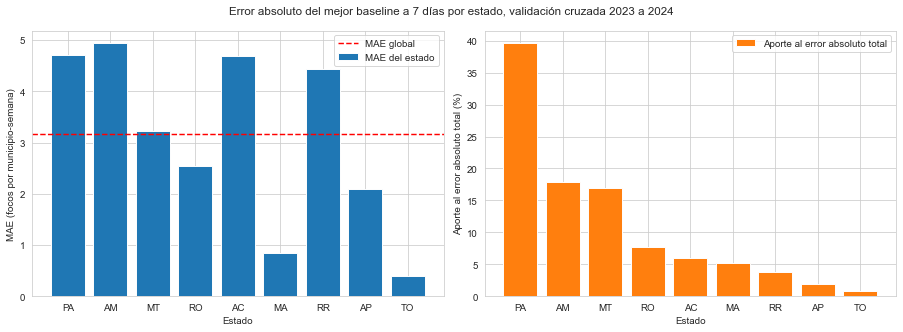

In [31]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
ejes[0].bar(por_uf.index, por_uf["MAE"], color="tab:blue", label="MAE del estado")
ejes[0].axhline(p_mejor["error_abs"].mean(), color="red", linestyle="--", label="MAE global")
ejes[0].set_xlabel("Estado")
ejes[0].set_ylabel("MAE (focos por municipio-semana)")
ejes[0].legend()
ejes[1].bar(por_uf.index, por_uf["aporte_error_pct"], color="tab:orange", label="Aporte al error absoluto total")
ejes[1].set_xlabel("Estado")
ejes[1].set_ylabel("Aporte al error absoluto total (%)")
ejes[1].legend()
fig.suptitle("Error absoluto del mejor baseline a 7 días por estado, validación cruzada 2023 a 2024")
plt.tight_layout()
plt.show()


**Figura 6.** A la izquierda, MAE del mejor baseline a 7 días por estado; a la derecha, el aporte de cada estado al error absoluto total. Predicciones de los 4 folds juntas, 2023 a 2024.


### Hallazgos de esta etapa

**Qué se observa**
- Con el mejor baseline a 7 días (Regresión Lineal con SISAM), Pará aporta **39.601 %** del error absoluto (MAE **4.719**), Amazonas **17.848 %** (**4.940**) y Mato Grosso **16.929 %** (**3.228**). Acre tiene un MAE de **4.690** y Tocantins de **0.400**.
- La temporada seca concentra **85.511 %** del error (MAE **6.203** y sesgo de **-4.082**), frente a un MAE de **0.811** en la húmeda (ver Figura 6).
- Los 10 municipios con mayor error acumulado aportan **24.0 %** del total (de **543** municipios): `SAO FELIX DO XINGU` (**4.27 %**) y `ALTAMIRA` (**3.98 %**) encabezan la lista.
- El **1 %** de las filas con mayor error aporta **42.2 %** del error absoluto, y el **10 %** aporta **81.1 %**.

**Por qué importa**
- El error no está dominado por pocos municipios (10 municipios suman **24.0 %**), sino por **semanas extremas** de la temporada seca, donde el modelo subestima los picos (sesgo de **-4.082**).

**Qué implica para el modelado avanzado**
- Los modelos avanzados deben mejorar la predicción de picos en la temporada seca, y las métricas se reportan por temporada y por estado, no solo en promedio.
- **Limitación:** el análisis usa las predicciones de validación de 2023 a 2024; no se usó 2025.


### Conclusiones

- **Valores iniciales a vencer:** a 7 días, MAE **3.274** (Regresión Lineal con SISAM) y RMSE **14.205** (persistencia); a 30 días, MAE **12.271** y RMSE **52.938** (árbol sin SISAM); en el Frente 2, accuracy **0.686**, F1 macro **0.555** y recall de Crítico **0.545** (persistencia); en la alerta, recall **0.579** (persistencia) con falsas alarmas **0.014** (lineal).
- **Ningún modelo base gana todas las métricas:** la persistencia es el mejor baseline del Frente 2 y del RMSE, y la lineal lo es del MAE a 7 días. Los modelos del Hito 2 reajustados mejoran poco a la persistencia y no la superan en el Frente 2.
- **Variabilidad:** la desviación entre folds es del mismo orden que el promedio (MAE **3.461** con desviación **3.130** en la persistencia), por eso los criterios se expresan como mejora relativa y en número de folds.
- **Dónde está el error:** en los picos. Con más de 20 focos reales, el MAE de la lineal es **49.062** y su sesgo **-43.898**; la temporada seca concentra el **85.511 %** del error y el **1 %** de las filas con mayor error aporta el **42.2 %**.
- **SISAM:** en esta primera lectura no aporta (diferencias de MAE menores que 0.2). Se confirma en la ablación del notebook avanzado.
- **2025:** el MAE cae cerca de 60 % por el cambio de nivel (**-69.1 %** de focos), no por mejora de los modelos.
- **Para el modelado avanzado:** reducir **10 %** el MAE del mejor baseline en al menos 3 de 4 folds, y en el Frente 2 alcanzar F1 macro de **0.615** y recall de Crítico de **0.645**.


### Resumen para el informe

- **Evaluación:** entrenamiento 2022-01-31 a 2024-12-02 (**80,907** filas), validación cruzada expansiva con **4** folds y margen de 4 semanas, y prueba 2025 (**27,693** filas) evaluada una sola vez. 2026 no se usa.
- **Métricas iniciales a 7 días** (validación; 2025): MAE **3.274** (**1.295**) con la Regresión Lineal con SISAM, RMSE **14.205** (**5.291**) y sesgo **-0.022** (**-0.029**) con la persistencia, MAE solo con focos **7.015** (**4.236**) y R² en `log1p` **0.562** (**0.532**).
- **Métricas iniciales a 30 días** (validación; 2025): MAE **12.271** (**5.025**) y RMSE **52.938** (**21.429**) con el árbol sin SISAM, y R² en `log1p` **0.594** (**0.597**) con la lineal con SISAM.
- **Frente 2** (validación; 2025): la persistencia de clase da accuracy **0.686** (**0.582**), F1 macro **0.555** (**0.562**), recall de Crítico **0.545** (**0.635**) y error ordinal **0.393** (**0.527**). Los árboles base no la superan en validación (F1 macro de **0.497** a **0.521**).
- **KPI de alerta a 7 días** (validación; 2025): recall **0.579** (**0.510**) con la persistencia, y precisión **0.743** (**0.671**) y falsas alarmas **0.014** (**0.008**) con la lineal con SISAM.
- **Coherencia:** la persistencia sobre todo el entrenamiento (MAE **3.364** y accuracy **65.9 %**) coincide con el EDA (**3.343** y **66.1 %**).
- **Dónde está el error:** Pará aporta **39.601 %** del error, la temporada seca **85.511 %** y el **1 %** de las filas con mayor error **42.2 %**. Con más de 20 focos reales la lineal tiene sesgo de **-43.898**: los modelos subestiman los picos.
- **SISAM:** en la primera lectura no aporta (MAE con y sin SISAM difieren menos de 0.2); la ablación completa se hace en el modelado avanzado.
- **Criterios de éxito propuestos:** reducir **10 %** el MAE del mejor baseline (a 7 días, **2.946**; a 30 días, **11.044**) en al menos 3 de 4 folds; Frente 2 con F1 macro de **0.615** y recall de Crítico de **0.645**. KPI de control provisionales: MAE móvil de 4 semanas menor que **6.408**, recall de alerta de al menos **0.360** y falsas alarmas de a lo sumo **0.026**.
- **Limitaciones:** el MAE de 2025 cae cerca de 60 % por el cambio de nivel (**-69.1 %** en los focos) y no es comparable con la validación; los parámetros de preparación se ajustaron con todo el entrenamiento y no por fold; y el Frente 2 es en parte función del clima porque `riesgo_fuego_promedio` lo calcula INPE a partir de variables climáticas.
